# Lista de Exercícios — Inteligência Artificial

**Alunos:** Antônio Rodrigo Lima de Andrade Tenório (23210707); Bruno Gomes de Barros Filho (21111360)

**Disciplina:** Inteligência Artificial

**Professor:** Evandro Costa

**Data:** outubro de 2026

## Introdução

Esta lista trata de duas formas de construir a base de conhecimento de um sistema inteligente. A primeira é **aprender regras a partir de exemplos**, usando árvores de decisão (ID3, C4.5 e CART) e indução direta de regras (PRISM). A segunda é **usar regras para raciocinar**, por meio de um shell de sistema especialista com encadeamento para frente, para trás e misto.

As questões 1 e 2 usam a base de risco de crédito do livro do Luger, ampliada para 30 exemplos e 6 atributos. As questões 3 e 4 usam a base Pima Indians Diabetes, do Kaggle. A questão 5 desenvolve um shell genérico em Python.

Cada questão segue a mesma estrutura: **Enunciado**, **Raciocínio**, **Resolução** e **Conclusão**. Quando a questão tem itens, cada item segue essa estrutura.

In [ ]:
!pip install -q chefboost
import warnings, re, io, contextlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from chefboost import Chefboost as chef
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option("display.max_rows", 100)

---
# Questão 1

## Enunciado

Considere a base de dados seguinte, supostamente fornecida pelo "gerente do banco", realizando nela a seguinte ampliação:

(i) aumentá-la para que contenha 6 atributos e 30 exemplos (E15, E16, ..., E30), com a adição de 16 exemplos, distribuídos entre Risco = Baixo, Risco = Alto e Risco = Moderado;

(ii) a partir da base de dados ampliada (conforme feito em (i)), construa "manualmente" e apresente 3 árvores de decisão, sendo uma usando o algoritmo ID3, outra com o C4.5 e uma última com o algoritmo CART;

(iii) de cada uma das 3 árvores de decisão obtidas em (ii), extraia e apresente as respectivas bases de conhecimento com regras do tipo SE...ENTÃO...;

(iv) compare as 3 bases de regras e selecione, justificando sua escolha, a que você julga mais apropriada para ser a base de conhecimento a ser usada na solução do problema de análise de risco de crédito, discutido em sala de aula.

Base original

| | História de Crédito | Dívida | Garantia | Renda | Risco |
|---|---|---|---|---|---|
| E1 | Ruim | Alta | Nenhuma | \$0 a \$15k | Alto |
| E2 | Desconhecida | Alta | Nenhuma | \$15 a \$35k | Alto |
| E3 | Desconhecida | Baixa | Nenhuma | \$15 a \$35k | Moderado |
| E4 | Desconhecida | Baixa | Nenhuma | \$0 a \$15k | Alto |
| E5 | Desconhecida | Baixa | Nenhuma | Acima de \$35k | Baixo |
| E6 | Desconhecida | Baixa | Adequada | Acima de \$35k | Baixo |
| E7 | Ruim | Baixa | Nenhuma | \$0 a \$15k | Alto |
| E8 | Ruim | Baixa | Adequada | Acima de \$35k | Moderado |
| E9 | Boa | Baixa | Nenhuma | Acima de \$35k | Baixo |
| E10 | Boa | Alta | Adequada | Acima de \$35k | Baixo |
| E11 | Boa | Alta | Nenhuma | \$0 a \$15k | Alto |
| E12 | Boa | Alta | Nenhuma | \$15 a \$35k | Moderado |
| E13 | Boa | Alta | Nenhuma | Acima de \$35k | Baixo |
| E14 | Ruim | Alta | Nenhuma | \$15 a \$35k | Alto |

## Item (i) — Ampliação da base

### Enunciado
Aumentar a base para 6 atributos e 30 exemplos (E15 a E30), adicionando 16 exemplos distribuídos entre Risco = Baixo, Alto e Moderado.

### Raciocínio
Para chegar a 6 atributos, foram escolhidos dois atributos que um gerente de banco realmente usaria: **Emprego** (Estável ou Instável) e **Imóvel** (Próprio ou Alugado). Os exemplos E1 a E14 foram mantidos como estavam e só receberam os valores dos dois atributos novos, de forma coerente com o risco de cada um. Os 16 exemplos novos foram criados de modo a misturar as três classes e a fazer sentido para o negócio. Por exemplo, renda baixa com imóvel alugado tende a risco alto.

### Resolução
Na tabela, as faixas de renda aparecem abreviadas: `0-15` = 0 a 15k, `15-35` = 15 a 35k e `>35` = acima de 35k.

In [ ]:
raw = """E1 Ruim Alta Nenhuma 0-15 Instavel Alugado Alto
E2 Desconhecida Alta Nenhuma 15-35 Instavel Alugado Alto
E3 Desconhecida Baixa Nenhuma 15-35 Estavel Alugado Moderado
E4 Desconhecida Baixa Nenhuma 0-15 Instavel Alugado Alto
E5 Desconhecida Baixa Nenhuma >35 Estavel Proprio Baixo
E6 Desconhecida Baixa Adequada >35 Estavel Proprio Baixo
E7 Ruim Baixa Nenhuma 0-15 Instavel Alugado Alto
E8 Ruim Baixa Adequada >35 Estavel Alugado Moderado
E9 Boa Baixa Nenhuma >35 Estavel Proprio Baixo
E10 Boa Alta Adequada >35 Estavel Proprio Baixo
E11 Boa Alta Nenhuma 0-15 Instavel Alugado Alto
E12 Boa Alta Nenhuma 15-35 Estavel Alugado Moderado
E13 Boa Alta Nenhuma >35 Estavel Alugado Baixo
E14 Ruim Alta Nenhuma 15-35 Instavel Alugado Alto
E15 Boa Baixa Adequada 15-35 Estavel Proprio Baixo
E16 Boa Baixa Nenhuma 15-35 Estavel Proprio Baixo
E17 Desconhecida Baixa Adequada >35 Instavel Proprio Moderado
E18 Ruim Alta Nenhuma >35 Estavel Alugado Moderado
E19 Desconhecida Alta Nenhuma 0-15 Estavel Alugado Alto
E20 Boa Baixa Adequada >35 Estavel Alugado Baixo
E21 Ruim Baixa Nenhuma 15-35 Estavel Alugado Moderado
E22 Boa Alta Adequada 15-35 Estavel Proprio Moderado
E23 Ruim Alta Adequada 0-15 Instavel Proprio Alto
E24 Desconhecida Baixa Nenhuma 15-35 Instavel Proprio Moderado
E25 Boa Baixa Nenhuma 0-15 Estavel Proprio Moderado
E26 Ruim Baixa Nenhuma >35 Instavel Alugado Alto
E27 Desconhecida Alta Adequada >35 Estavel Proprio Baixo
E28 Ruim Alta Nenhuma 15-35 Estavel Alugado Alto
E29 Boa Baixa Nenhuma >35 Instavel Proprio Baixo
E30 Desconhecida Baixa Nenhuma 0-15 Estavel Alugado Alto"""
linhas = [l.split() for l in raw.strip().split("\n")]
cols = ["Historia","Divida","Garantia","Renda","Emprego","Imovel","Risco"]
df = pd.DataFrame([l[1:] for l in linhas], columns=cols, index=[l[0] for l in linhas]).astype(object)
atributos = cols[:-1]
print("Distribuição das classes:", df["Risco"].value_counts().to_dict())
df

Distribuição das classes: {'Alto': 11, 'Baixo': 10, 'Moderado': 9}


,Historia,Divida,Garantia,Renda,Emprego,Imovel,Risco
E1,Ruim,Alta,Nenhuma,0-15,Instavel,Alugado,Alto
E2,Desconhecida,Alta,Nenhuma,15-35,Instavel,Alugado,Alto
E3,Desconhecida,Baixa,Nenhuma,15-35,Estavel,Alugado,Moderado
E4,Desconhecida,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E5,Desconhecida,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo
E6,Desconhecida,Baixa,Adequada,>35,Estavel,Proprio,Baixo
E7,Ruim,Baixa,Nenhuma,0-15,Instavel,Alugado,Alto
E8,Ruim,Baixa,Adequada,>35,Estavel,Alugado,Moderado
E9,Boa,Baixa,Nenhuma,>35,Estavel,Proprio,Baixo
E10,Boa,Alta,Adequada,>35,Estavel,Proprio,Baixo


In [ ]:
novos = df.loc[[f"E{i}" for i in range(15, 31)]]
print("Exemplos novos (E15 a E30) por classe:", novos["Risco"].value_counts().to_dict())
print("Base completa por classe:            ", df["Risco"].value_counts().to_dict())
print("Número de atributos:", len(atributos), "| Número de exemplos:", len(df))

Exemplos novos (E15 a E30) por classe: {'Moderado': 6, 'Baixo': 5, 'Alto': 5}
Base completa por classe:             {'Alto': 11, 'Baixo': 10, 'Moderado': 9}
Número de atributos: 6 | Número de exemplos: 30


### Conclusão
A base ficou com 6 atributos e 30 exemplos, como pedido. Os 16 exemplos novos se dividem em 5 de risco Baixo, 6 Moderado e 5 Alto. No total, a base tem 11 exemplos de risco Alto, 9 de Moderado e 10 de Baixo, uma distribuição bem equilibrada para construir as árvores.

## Item (ii) — Construção das três árvores

### Enunciado
Construir manualmente e apresentar 3 árvores de decisão a partir da base ampliada: uma com ID3, uma com C4.5 e uma com CART.

### Raciocínio
Os três algoritmos funcionam do mesmo jeito: em cada nó, escolhem o atributo que melhor separa as classes, dividem os exemplos e repetem o processo em cada parte, até os grupos ficarem puros. A diferença está na medida usada para escolher o atributo:

- **ID3** usa o **ganho de informação**, que mede quanto a entropia (a "mistura" das classes) diminui depois da divisão.
- **C4.5** usa a **razão de ganho**, que é o ganho dividido pelo split info. Isso penaliza atributos com muitos valores. Seguindo Quinlan, só concorrem os atributos com ganho pelo menos igual à média.
- **CART** usa o **índice Gini** e só faz divisões binárias (sim ou não).

Para fazer "manualmente", as fórmulas foram programadas do zero, sem biblioteca, e o código imprime cada conta.

---

Entropia:  $H(S) = -\sum_i p_i \log_2 p_i$

Ganho: $Ganho(S,A) = H(S) - \sum_v \frac{|S_v|}{|S|} H(S_v)$

Split info: $SI(S,A) = -\sum_v \frac{|S_v|}{|S|}\log_2\frac{|S_v|}{|S|}$

Razão de ganho: $RG(S,A) = Ganho(S,A) / SI(S,A)$

Gini: $Gini(S) = 1 - \sum_i p_i^2$

---

### Resolução

**Funções das medidas**

In [ ]:
from math import log2
from collections import Counter
from itertools import combinations
ALVO = "Risco"

def contar(S):        return Counter(S[ALVO])
def entropia(S):      n = len(S); return -sum((c/n) * log2(c/n) for c in contar(S).values())
def gini(S):          n = len(S); return 1 - sum((c/n)**2 for c in contar(S).values())
def particoes(S, a):  return {v: S[S[a] == v] for v in sorted(S[a].unique())}
def ganho(S, a):      return entropia(S) - sum(len(Sv)/len(S) * entropia(Sv) for Sv in particoes(S, a).values())
def split_info(S, a): return -sum(len(Sv)/len(S) * log2(len(Sv)/len(S)) for Sv in particoes(S, a).values())
def razao_ganho(S, a):
    si = split_info(S, a); return ganho(S, a) / si if si > 0 else 0

print(f"Entropia da base inteira: {entropia(df):.3f}")
print(f"Gini da base inteira:     {gini(df):.3f}")

Entropia da base inteira: 1.580
Gini da base inteira:     0.664


**Cálculo detalhado para o atributo Renda na raiz**

In [ ]:
def explicar_entropia(S, nome):
    n, c = len(S), contar(S)
    termos = " ".join(f"- {k}/{n}·log2({k}/{n})" for k in c.values())
    print(f"  H({nome}) = {termos} = {entropia(S):.3f}    {dict(c)}")

def explicar_ganho(S, a):
    print(f"=== Atributo {a} ===")
    explicar_entropia(S, "S")
    parts = particoes(S, a)
    for v, Sv in parts.items():
        explicar_entropia(Sv, f"{a}={v}")
    media = sum(len(Sv)/len(S) * entropia(Sv) for Sv in parts.values())
    print("  Média ponderada = " + " + ".join(f"{len(Sv)}/{len(S)}·{entropia(Sv):.3f}" for Sv in parts.values()) + f" = {media:.3f}")
    print(f"  Ganho({a}) = {entropia(S):.3f} - {media:.3f} = {ganho(S, a):.3f}")
    print(f"  SplitInfo({a}) = " + " ".join(f"- {len(Sv)}/{len(S)}·log2({len(Sv)}/{len(S)})" for Sv in parts.values()) + f" = {split_info(S, a):.3f}")
    print(f"  Razão de ganho({a}) = {ganho(S, a):.3f} / {split_info(S, a):.3f} = {razao_ganho(S, a):.3f}")

explicar_ganho(df, "Renda")

=== Atributo Renda ===
  H(S) = - 11/30·log2(11/30) - 9/30·log2(9/30) - 10/30·log2(10/30) = 1.580    {'Alto': 11, 'Moderado': 9, 'Baixo': 10}
  H(Renda=0-15) = - 7/8·log2(7/8) - 1/8·log2(1/8) = 0.544    {'Alto': 7, 'Moderado': 1}
  H(Renda=15-35) = - 3/10·log2(3/10) - 5/10·log2(5/10) - 2/10·log2(2/10) = 1.485    {'Alto': 3, 'Moderado': 5, 'Baixo': 2}
  H(Renda=>35) = - 8/12·log2(8/12) - 3/12·log2(3/12) - 1/12·log2(1/12) = 1.189    {'Baixo': 8, 'Moderado': 3, 'Alto': 1}
  Média ponderada = 8/30·0.544 + 10/30·1.485 + 12/30·1.189 = 1.116
  Ganho(Renda) = 1.580 - 1.116 = 0.465
  SplitInfo(Renda) = - 8/30·log2(8/30) - 10/30·log2(10/30) - 12/30·log2(12/30) = 1.566
  Razão de ganho(Renda) = 0.465 / 1.566 = 0.297


**Comparação de todos os atributos na raiz**

In [ ]:
raiz = pd.DataFrame({a: {"Ganho (ID3)": ganho(df, a), "SplitInfo": split_info(df, a),
                         "Razão de ganho (C4.5)": razao_ganho(df, a)} for a in atributos}).T.round(3)
raiz["Ganho ≥ média?"] = raiz["Ganho (ID3)"] >= raiz["Ganho (ID3)"].mean()
raiz.sort_values("Ganho (ID3)", ascending=False)

,Ganho (ID3),SplitInfo,Razão de ganho (C4.5),Ganho ≥ média?
Renda,0.465,1.566,0.297,True
Historia,0.326,1.580,0.206,True
Imovel,0.288,0.987,0.292,True
Emprego,0.253,0.948,0.266,True
Garantia,0.111,0.881,0.126,False
Divida,0.071,0.987,0.072,False


Renda tem o maior ganho (0,465) e também a maior razão de ganho (0,297) entre os atributos com ganho acima da média. Por isso Renda é a raiz no ID3 e no C4.5.

**Construção recursiva (ID3 e C4.5)**

A função abaixo aplica a mesma conta em cada nó e imprime o caminho até o nó, as classes presentes, o valor de cada atributo candidato e o atributo escolhido.

In [ ]:
def construir(S, atrs, criterio="id3", caminho="raiz", verbose=True):
    c = contar(S)
    if len(c) == 1:                       # nó puro → folha
        return {"folha": next(iter(c)), "exemplos": list(S.index)}
    if not atrs:                          # acabaram os atributos → classe majoritária
        return {"folha": c.most_common(1)[0][0], "exemplos": list(S.index)}
    g = {a: ganho(S, a) for a in atrs}; rg = {a: razao_ganho(S, a) for a in atrs}
    if criterio == "id3":
        melhor = max(atrs, key=lambda a: g[a]); metr = g
    else:                                 # C4.5: só atributos com ganho >= média
        media = sum(g.values()) / len(g)
        cands = [a for a in atrs if g[a] >= media - 1e-9]
        melhor = max(cands, key=lambda a: rg[a]); metr = rg
    if verbose:
        print(f"{caminho}  ({len(S)} ex. {dict(c)})")
        print("    " + ", ".join(f"{a}={metr[a]:.3f}" for a in atrs) + f"  →  escolhe {melhor}")
    filhos = {v: construir(Sv, [a for a in atrs if a != melhor], criterio, f"{caminho} > {melhor}={v}", verbose)
              for v, Sv in particoes(S, melhor).items()}
    return {"atributo": melhor, "filhos": filhos, "maioria": c.most_common(1)[0][0]}

def imprimir(no, prefixo=""):
    for k, (v, filho) in enumerate(no["filhos"].items()):
        ult = k == len(no["filhos"]) - 1
        ramo, cont = ("└── ", "    ") if ult else ("├── ", "│   ")
        if "folha" in filho:
            print(f"{prefixo}{ramo}{v} → {filho['folha'].upper()}  {filho['exemplos']}")
        else:
            print(f"{prefixo}{ramo}{v} → [{filho['atributo']}]"); imprimir(filho, prefixo + cont)

def regras_arvore(no, conds=()):
    if "folha" in no: return [(list(conds), no["folha"])]
    out = []
    for v, filho in no["filhos"].items():
        out += regras_arvore(filho, conds + (f"{no['atributo']} = {v}",))
    return out

def mostrar_regras(regras, alvo="Risco"):
    for i, (conds, cls) in enumerate(regras, 1):
        print(f"R{i:02d}: SE " + " E ".join(conds) + f" ENTÃO {alvo} = {cls}")

**Árvore ID3** (critério: ganho de informação)

In [ ]:
arv_id3 = construir(df, atributos, "id3")

raiz  (30 ex. {'Alto': 11, 'Moderado': 9, 'Baixo': 10})
    Historia=0.326, Divida=0.071, Garantia=0.111, Renda=0.465, Emprego=0.253, Imovel=0.288  →  escolhe Renda
raiz > Renda=0-15  (8 ex. {'Alto': 7, 'Moderado': 1})
    Historia=0.294, Divida=0.138, Garantia=0.026, Emprego=0.199, Imovel=0.294  →  escolhe Historia
raiz > Renda=0-15 > Historia=Boa  (2 ex. {'Alto': 1, 'Moderado': 1})
    Divida=1.000, Garantia=0.000, Emprego=1.000, Imovel=1.000  →  escolhe Divida
raiz > Renda=15-35  (10 ex. {'Alto': 3, 'Moderado': 5, 'Baixo': 2})
    Historia=0.534, Divida=0.515, Garantia=0.161, Emprego=0.245, Imovel=0.485  →  escolhe Historia
raiz > Renda=15-35 > Historia=Boa  (4 ex. {'Moderado': 2, 'Baixo': 2})
    Divida=1.000, Garantia=0.000, Emprego=0.000, Imovel=0.311  →  escolhe Divida
raiz > Renda=15-35 > Historia=Desconhecida  (3 ex. {'Alto': 1, 'Moderado': 2})
    Divida=0.918, Garantia=0.000, Emprego=0.252, Imovel=0.252  →  escolhe Divida
raiz > Renda=15-35 > Historia=Ruim  (3 ex. {'Alto': 2

In [ ]:
print(f"[{arv_id3['atributo']}]"); imprimir(arv_id3)

[Renda]
├── 0-15 → [Historia]
│   ├── Boa → [Divida]
│   │   ├── Alta → ALTO  ['E11']
│   │   └── Baixa → MODERADO  ['E25']
│   ├── Desconhecida → ALTO  ['E4', 'E19', 'E30']
│   └── Ruim → ALTO  ['E1', 'E7', 'E23']
├── 15-35 → [Historia]
│   ├── Boa → [Divida]
│   │   ├── Alta → MODERADO  ['E12', 'E22']
│   │   └── Baixa → BAIXO  ['E15', 'E16']
│   ├── Desconhecida → [Divida]
│   │   ├── Alta → ALTO  ['E2']
│   │   └── Baixa → MODERADO  ['E3', 'E24']
│   └── Ruim → [Divida]
│       ├── Alta → ALTO  ['E14', 'E28']
│       └── Baixa → MODERADO  ['E21']
└── >35 → [Historia]
    ├── Boa → BAIXO  ['E9', 'E10', 'E13', 'E20', 'E29']
    ├── Desconhecida → [Emprego]
    │   ├── Estavel → BAIXO  ['E5', 'E6', 'E27']
    │   └── Instavel → MODERADO  ['E17']
    └── Ruim → [Emprego]
        ├── Estavel → MODERADO  ['E8', 'E18']
        └── Instavel → ALTO  ['E26']


No nó `Renda=0-15`, História e Imóvel empataram com ganho 0,294. O critério de desempate adotado foi a ordem dos atributos na tabela, por isso História foi escolhida.

**Árvore C4.5** (critério: razão de ganho)

In [ ]:
arv_c45 = construir(df, atributos, "c45")

raiz  (30 ex. {'Alto': 11, 'Moderado': 9, 'Baixo': 10})
    Historia=0.206, Divida=0.072, Garantia=0.126, Renda=0.297, Emprego=0.266, Imovel=0.292  →  escolhe Renda
raiz > Renda=0-15  (8 ex. {'Alto': 7, 'Moderado': 1})
    Historia=0.188, Divida=0.138, Garantia=0.048, Emprego=0.209, Imovel=0.362  →  escolhe Imovel
raiz > Renda=0-15 > Imovel=Proprio  (2 ex. {'Alto': 1, 'Moderado': 1})
    Historia=1.000, Divida=1.000, Garantia=1.000, Emprego=1.000  →  escolhe Historia
raiz > Renda=15-35  (10 ex. {'Alto': 3, 'Moderado': 5, 'Baixo': 2})
    Historia=0.340, Divida=0.515, Garantia=0.223, Emprego=0.278, Imovel=0.500  →  escolhe Divida
raiz > Renda=15-35 > Divida=Alta  (5 ex. {'Alto': 3, 'Moderado': 2})
    Historia=0.638, Garantia=0.446, Emprego=0.433, Imovel=0.446  →  escolhe Historia
raiz > Renda=15-35 > Divida=Baixa  (5 ex. {'Moderado': 3, 'Baixo': 2})
    Historia=0.638, Garantia=0.446, Emprego=0.237, Imovel=0.433  →  escolhe Historia
raiz > Renda=>35  (12 ex. {'Baixo': 8, 'Moderado': 3,

In [ ]:
print(f"[{arv_c45['atributo']}]"); imprimir(arv_c45)

[Renda]
├── 0-15 → [Imovel]
│   ├── Alugado → ALTO  ['E1', 'E4', 'E7', 'E11', 'E19', 'E30']
│   └── Proprio → [Historia]
│       ├── Boa → MODERADO  ['E25']
│       └── Ruim → ALTO  ['E23']
├── 15-35 → [Divida]
│   ├── Alta → [Historia]
│   │   ├── Boa → MODERADO  ['E12', 'E22']
│   │   ├── Desconhecida → ALTO  ['E2']
│   │   └── Ruim → ALTO  ['E14', 'E28']
│   └── Baixa → [Historia]
│       ├── Boa → BAIXO  ['E15', 'E16']
│       ├── Desconhecida → MODERADO  ['E3', 'E24']
│       └── Ruim → MODERADO  ['E21']
└── >35 → [Historia]
    ├── Boa → BAIXO  ['E9', 'E10', 'E13', 'E20', 'E29']
    ├── Desconhecida → [Emprego]
    │   ├── Estavel → BAIXO  ['E5', 'E6', 'E27']
    │   └── Instavel → MODERADO  ['E17']
    └── Ruim → [Emprego]
        ├── Estavel → MODERADO  ['E8', 'E18']
        └── Instavel → ALTO  ['E26']


Em `Renda=0-15 > Imovel=Proprio`, não há nenhum exemplo com História = Desconhecida, então esse ramo não aparece. Pela regra do C4.5, um caso assim receberia a classe majoritária do nó pai, que é Alto.

**Árvore CART** (critério: Gini, divisões binárias)

Em cada nó, a função testa todas as perguntas de sim ou não possíveis e escolhe a de menor Gini ponderado. A linha "top 3" mostra as três melhores candidatas.

In [ ]:
def construir_cart(S, caminho="raiz", verbose=True):
    c = contar(S)
    if len(c) == 1: return {"folha": next(iter(c)), "exemplos": list(S.index)}
    cands = []
    for a in atributos:
        vals = sorted(S[a].unique())
        for k in range(1, len(vals) // 2 + 1):
            for sub in combinations(vals, k):
                L, R = S[S[a].isin(sub)], S[~S[a].isin(sub)]
                g = len(L)/len(S) * gini(L) + len(R)/len(S) * gini(R)
                cands.append((g, a, sub))
    cands.sort(key=lambda t: t[0])
    g, a, sub = cands[0]
    if gini(S) - g < 1e-9: return {"folha": c.most_common(1)[0][0], "exemplos": list(S.index)}
    pergunta = f"{a} = {sub[0]}" if len(sub) == 1 else f"{a} ∈ {set(sub)}"
    if verbose:
        print(f"{caminho}  ({len(S)} ex. {dict(c)}, Gini={gini(S):.3f})")
        print("    top 3: " + " | ".join(f"{x[1]}={x[2][0] if len(x[2])==1 else x[2]}: {x[0]:.3f}" for x in cands[:3]) + f"  →  {pergunta}?")
    m = S[a].isin(sub)
    return {"pergunta": pergunta, "atr": a, "sub": sub,
            "SIM": construir_cart(S[m], f"{caminho} > {pergunta}", verbose),
            "NAO": construir_cart(S[~m], f"{caminho} > NÃO({pergunta})", verbose)}

def imprimir_cart(no, prefixo=""):
    for k, ramo in enumerate(["SIM", "NAO"]):
        filho = no[ramo]; ult = k == 1
        r, cont = ("└── ", "    ") if ult else ("├── ", "│   ")
        nome = "SIM" if ramo == "SIM" else "NÃO"
        if "folha" in filho: print(f"{prefixo}{r}{nome} → {filho['folha'].upper()}  {filho['exemplos']}")
        else: print(f"{prefixo}{r}{nome} → [{filho['pergunta']}?]"); imprimir_cart(filho, prefixo + cont)

def regras_cart(no, conds=()):
    if "folha" in no: return [(list(conds), no["folha"])]
    neg = no["pergunta"].replace(" = ", " ≠ ") if len(no["sub"]) == 1 else f"{no['atr']} ∉ {set(no['sub'])}"
    return regras_cart(no["SIM"], conds + (no["pergunta"],)) + regras_cart(no["NAO"], conds + (neg,))

arv_cart = construir_cart(df)

raiz  (30 ex. {'Alto': 11, 'Moderado': 9, 'Baixo': 10}, Gini=0.664)
    top 3: Renda=0-15: 0.519 | Renda=>35: 0.535 | Imovel=Alugado: 0.539  →  Renda = 0-15?
raiz > Renda = 0-15  (8 ex. {'Alto': 7, 'Moderado': 1}, Gini=0.219)
    top 3: Historia=Boa: 0.125 | Imovel=Alugado: 0.125 | Imovel=Proprio: 0.125  →  Historia = Boa?
raiz > Renda = 0-15 > Historia = Boa  (2 ex. {'Alto': 1, 'Moderado': 1}, Gini=0.500)
    top 3: Divida=Alta: 0.000 | Divida=Baixa: 0.000 | Emprego=Estavel: 0.000  →  Divida = Alta?
raiz > NÃO(Renda = 0-15)  (22 ex. {'Alto': 4, 'Moderado': 8, 'Baixo': 10}, Gini=0.628)
    top 3: Historia=Ruim: 0.506 | Imovel=Alugado: 0.512 | Imovel=Proprio: 0.512  →  Historia = Ruim?
raiz > NÃO(Renda = 0-15) > Historia = Ruim  (6 ex. {'Moderado': 3, 'Alto': 3}, Gini=0.500)
    top 3: Emprego=Estavel: 0.250 | Emprego=Instavel: 0.250 | Garantia=Adequada: 0.400  →  Emprego = Estavel?
raiz > NÃO(Renda = 0-15) > Historia = Ruim > Emprego = Estavel  (4 ex. {'Moderado': 3, 'Alto': 1}, Gini=0

In [ ]:
print(f"[{arv_cart['pergunta']}?]"); imprimir_cart(arv_cart)

[Renda = 0-15?]
├── SIM → [Historia = Boa?]
│   ├── SIM → [Divida = Alta?]
│   │   ├── SIM → ALTO  ['E11']
│   │   └── NÃO → MODERADO  ['E25']
│   └── NÃO → ALTO  ['E1', 'E4', 'E7', 'E19', 'E23', 'E30']
└── NÃO → [Historia = Ruim?]
    ├── SIM → [Emprego = Estavel?]
    │   ├── SIM → [Divida = Alta?]
    │   │   ├── SIM → [Renda = 15-35?]
    │   │   │   ├── SIM → ALTO  ['E28']
    │   │   │   └── NÃO → MODERADO  ['E18']
    │   │   └── NÃO → MODERADO  ['E8', 'E21']
    │   └── NÃO → ALTO  ['E14', 'E26']
    └── NÃO → [Renda = 15-35?]
        ├── SIM → [Historia = Boa?]
        │   ├── SIM → [Divida = Alta?]
        │   │   ├── SIM → MODERADO  ['E12', 'E22']
        │   │   └── NÃO → BAIXO  ['E15', 'E16']
        │   └── NÃO → [Divida = Alta?]
        │       ├── SIM → ALTO  ['E2']
        │       └── NÃO → MODERADO  ['E3', 'E24']
        └── NÃO → [Emprego = Estavel?]
            ├── SIM → BAIXO  ['E5', 'E6', 'E9', 'E10', 'E13', 'E20', 'E27']
            └── NÃO → [Historia = Boa?]
  

### Conclusão
As três árvores começam por **Renda**, o que mostra que a faixa de renda é o atributo que mais separa o risco nessa base. A partir daí elas diferem:

- O **ID3** usa História em todos os ramos do segundo nível.
- O **C4.5** troca História por Imóvel e Dívida em dois ramos. Esses atributos têm só 2 valores e, por isso, dividem menos os dados.
- O **CART** gera uma árvore mais funda, com até 5 perguntas no mesmo caminho, porque cada pergunta só divide em dois.

Todas as folhas ficaram puras, ou seja, cada folha tem exemplos de uma única classe.

## Item (iii) — Bases de regras SE...ENTÃO

### Enunciado
Extrair e apresentar, de cada árvore obtida em (ii), a base de conhecimento com regras do tipo SE...ENTÃO.

### Raciocínio
Cada caminho da raiz até uma folha vira uma regra. As perguntas ao longo do caminho formam as condições, ligadas por **E**, e a folha é a conclusão. Assim, o número de regras é igual ao número de folhas da árvore.

### Resolução

In [ ]:
R1_id3, R1_c45, R1_cart = regras_arvore(arv_id3), regras_arvore(arv_c45), regras_cart(arv_cart)
print(f"===== ID3: {len(R1_id3)} regras"); mostrar_regras(R1_id3)
print(f"\n===== C4.5: {len(R1_c45)} regras"); mostrar_regras(R1_c45)
print(f"\n===== CART: {len(R1_cart)} regras"); mostrar_regras(R1_cart)

===== ID3: 15 regras
R01: SE Renda = 0-15 E Historia = Boa E Divida = Alta ENTÃO Risco = Alto
R02: SE Renda = 0-15 E Historia = Boa E Divida = Baixa ENTÃO Risco = Moderado
R03: SE Renda = 0-15 E Historia = Desconhecida ENTÃO Risco = Alto
R04: SE Renda = 0-15 E Historia = Ruim ENTÃO Risco = Alto
R05: SE Renda = 15-35 E Historia = Boa E Divida = Alta ENTÃO Risco = Moderado
R06: SE Renda = 15-35 E Historia = Boa E Divida = Baixa ENTÃO Risco = Baixo
R07: SE Renda = 15-35 E Historia = Desconhecida E Divida = Alta ENTÃO Risco = Alto
R08: SE Renda = 15-35 E Historia = Desconhecida E Divida = Baixa ENTÃO Risco = Moderado
R09: SE Renda = 15-35 E Historia = Ruim E Divida = Alta ENTÃO Risco = Alto
R10: SE Renda = 15-35 E Historia = Ruim E Divida = Baixa ENTÃO Risco = Moderado
R11: SE Renda = >35 E Historia = Boa ENTÃO Risco = Baixo
R12: SE Renda = >35 E Historia = Desconhecida E Emprego = Estavel ENTÃO Risco = Baixo
R13: SE Renda = >35 E Historia = Desconhecida E Emprego = Instavel ENTÃO Risco = 

### Conclusão
O ID3 gerou 15 regras, o C4.5 gerou 14 e o CART também gerou 14. A diferença mais visível é no tamanho das regras. As do ID3 e do C4.5 têm no máximo 3 condições. Já as do CART chegam a 5 condições e repetem o mesmo atributo, como Renda, dentro de uma regra.

## Item (iv) — Comparação e escolha da base de regras

### Enunciado
Comparar as 3 bases de regras e escolher, com justificativa, a mais apropriada para o problema de análise de risco de crédito.

### Raciocínio
Como as três árvores foram construídas até as folhas ficarem puras, todas acertam 100% dos exemplos. Então o acerto não serve para desempatar. A comparação deve olhar para o que importa numa base de conhecimento: quantidade de regras, tamanho das regras, facilidade de leitura e capacidade de generalizar para clientes novos.

### Resolução

In [ ]:
def acerto(regras, dados):
    ok = 0
    for _, ex in dados.iterrows():
        for conds, cls in regras:
            if all((ex[c.split(" ")[0]] == c.split(" ")[2]) == ("≠" not in c) for c in conds):
                ok += cls == ex["Risco"]; break
    return ok / len(dados)

pd.DataFrame({
  "Nº de regras": [len(R1_id3), len(R1_c45), len(R1_cart)],
  "Máx. condições": [max(len(c) for c, _ in R) for R in (R1_id3, R1_c45, R1_cart)],
  "Média de condições": [round(np.mean([len(c) for c, _ in R]), 2) for R in (R1_id3, R1_c45, R1_cart)],
  "Acerto no treino": [acerto(R, df) for R in (R1_id3, R1_c45, R1_cart)]}, index=["ID3", "C4.5", "CART"])

,Nº de regras,Máx. condições,Média de condições,Acerto no treino
ID3,15,3,2.80,1.0
C4.5,14,3,2.86,1.0
CART,14,5,4.21,1.0


Pontos observados:

1. **Tamanho:** C4.5 e CART têm 14 regras, e o ID3 tem 15. Mas o CART tem regras bem mais longas, com média de 4,2 condições e máximo de 5, contra média de cerca de 2,9 e máximo de 3 no C4.5.
2. **Generalidade:** a primeira regra do C4.5, "SE Renda = 0-15 E Imovel = Alugado ENTÃO Risco = Alto", cobre sozinha 6 clientes. No ID3, esses mesmos casos ficam espalhados em 3 regras.
3. **Robustez do método:** a razão de ganho corrige a tendência do ID3 de preferir atributos com muitos valores. O C4.5 também prevê poda, valores ausentes e atributos contínuos, o que é importante numa base real de banco.
4. **Legibilidade:** as regras do CART repetem atributos e usam negações ("≠"), o que dificulta a leitura por um analista de crédito.

### Conclusão
A base escolhida é a do **C4.5**. Ela tem o menor número de regras junto com o CART, mas suas regras são curtas (no máximo 3 condições), gerais e fáceis de explicar a um cliente ou a um órgão regulador. O CART seria uma boa opção para uma implementação automática com poda, mas para servir de base de conhecimento de um sistema especialista, o C4.5 entrega as regras mais claras.

---
# Questão 2

## Enunciado
Tal como feito em 1), construa e apresente as árvores de decisões geradas e suas bases de regras correspondentes, obtidas a partir do uso dos algoritmos ID3, C4.5 e CART, só que agora usando as implementações deles disponíveis em alguma biblioteca de "Machine Learning" (ex.: Scikit Learn ou R ou Weka, ...) ou se preferir, implemente os algoritmos e mostre o processo de construção e o resultado.

## Raciocínio
O scikit-learn só implementa o CART. Para ter os três algoritmos, foi usada também a biblioteca **chefboost**, que implementa ID3, C4.5 e CART e gera as regras como código Python (`if`/`elif`). Esse código é convertido em regras SE...ENTÃO. O CART também foi rodado no **scikit-learn**, que é a versão clássica com divisões binárias. Como a base é a mesma da questão 1, o resultado das bibliotecas deve bater com o que foi construído manualmente, e isso é verificado no final.

## Resolução

**Funções auxiliares** (treinar com o chefboost e converter o código gerado em regras)

In [ ]:
def treinar_chefboost(dados, algoritmo):
    d = dados.rename(columns={"Risco": "Decision"}).reset_index(drop=True).astype(object)
    with contextlib.redirect_stdout(io.StringIO()):
        modelo = chef.fit(d, {"algorithm": algoritmo}, target_label="Decision", silent=True)
    codigo = open("outputs/rules/rules.py").read()
    return modelo, codigo

def regras_chefboost(codigo, nomes):
    regras, pilha = [], []
    for linha in codigo.split("\n"):
        s = linha.strip(); ind = len(linha) - len(linha.lstrip())
        m = re.match(r"(?:el)?if obj\[(\d+)\] == '(.+)':", s)
        if m or s == "else:":
            pilha = [p for p in pilha if p[0] < ind]
            pilha.append((ind, f"{nomes[int(m.group(1))]} = {m.group(2)}" if m else None))
        elif s.startswith("return") and "def " not in s:
            conds = [c for i, c in pilha if i < ind]
            if conds and None not in conds:
                regras.append((conds, s.split("return")[1].strip().strip("'")))
    return regras

def mostrar_regras(regras, alvo="Risco"):
    for i, (conds, cls) in enumerate(regras, 1):
        print(f"R{i:02d}: SE " + " E ".join(conds) + f" ENTÃO {alvo} = {cls}")

def acuracia_treino(regras, dados):
    acertos = 0
    for _, ex in dados.iterrows():
        for conds, cls in regras:
            if all(ex[c.split(" = ")[0]] == c.split(" = ")[1] for c in conds):
                acertos += (cls == ex["Risco"]); break
    return acertos / len(dados)

atributos = cols[:-1]

**ID3 com chefboost.** O código gerado pela biblioteca é a própria árvore; os comentários `metric_value` mostram a entropia de cada nó.

In [ ]:
_, cod_id3 = treinar_chefboost(df, "ID3")
print(cod_id3)

def findDecision(obj): #obj[0]: Historia, obj[1]: Divida, obj[2]: Garantia, obj[3]: Renda, obj[4]: Emprego, obj[5]: Imovel
   # {"feature": "Renda", "instances": 30, "metric_value": 1.5801, "depth": 1}
   if obj[3] == '>35':
      # {"feature": "Historia", "instances": 12, "metric_value": 1.1887, "depth": 2}
      if obj[0] == 'Boa':
         return 'Baixo'
      elif obj[0] == 'Desconhecida':
         # {"feature": "Emprego", "instances": 4, "metric_value": 0.8113, "depth": 3}
         if obj[4] == 'Estavel':
            return 'Baixo'
         elif obj[4] == 'Instavel':
            return 'Moderado'
         else:
            return 'Baixo'
      elif obj[0] == 'Ruim':
         # {"feature": "Emprego", "instances": 3, "metric_value": 0.9183, "depth": 3}
         if obj[4] == 'Estavel':
            return 'Moderado'
         elif obj[4] == 'Instavel':
            return 'Alto'
         else:
            return 'Moderado'
      else:
         return 'Baixo'
   elif obj[3] == '15-35':
 

In [ ]:
r_id3 = regras_chefboost(cod_id3, atributos)
print(f"Base de regras ID3 — {len(r_id3)} regras\n"); mostrar_regras(r_id3)
print(f"\nAcurácia no treino: {acuracia_treino(r_id3, df):.0%}")

Base de regras ID3 — 15 regras

R01: SE Renda = >35 E Historia = Boa ENTÃO Risco = Baixo
R02: SE Renda = >35 E Historia = Desconhecida E Emprego = Estavel ENTÃO Risco = Baixo
R03: SE Renda = >35 E Historia = Desconhecida E Emprego = Instavel ENTÃO Risco = Moderado
R04: SE Renda = >35 E Historia = Ruim E Emprego = Estavel ENTÃO Risco = Moderado
R05: SE Renda = >35 E Historia = Ruim E Emprego = Instavel ENTÃO Risco = Alto
R06: SE Renda = 15-35 E Historia = Boa E Divida = Alta ENTÃO Risco = Moderado
R07: SE Renda = 15-35 E Historia = Boa E Divida = Baixa ENTÃO Risco = Baixo
R08: SE Renda = 15-35 E Historia = Desconhecida E Divida = Baixa ENTÃO Risco = Moderado
R09: SE Renda = 15-35 E Historia = Desconhecida E Divida = Alta ENTÃO Risco = Alto
R10: SE Renda = 15-35 E Historia = Ruim E Divida = Alta ENTÃO Risco = Alto
R11: SE Renda = 15-35 E Historia = Ruim E Divida = Baixa ENTÃO Risco = Moderado
R12: SE Renda = 0-15 E Historia = Ruim ENTÃO Risco = Alto
R13: SE Renda = 0-15 E Historia = Desc

**C4.5 com chefboost**

In [ ]:
_, cod_c45 = treinar_chefboost(df, "C4.5")
print(cod_c45)

def findDecision(obj): #obj[0]: Historia, obj[1]: Divida, obj[2]: Garantia, obj[3]: Renda, obj[4]: Emprego, obj[5]: Imovel
   # {"feature": "Renda", "instances": 30, "metric_value": 1.5801, "depth": 1}
   if obj[3] == '>35':
      # {"feature": "Historia", "instances": 12, "metric_value": 1.1887, "depth": 2}
      if obj[0] == 'Boa':
         return 'Baixo'
      elif obj[0] == 'Desconhecida':
         # {"feature": "Emprego", "instances": 4, "metric_value": 0.8113, "depth": 3}
         if obj[4] == 'Estavel':
            return 'Baixo'
         elif obj[4] == 'Instavel':
            return 'Moderado'
         else:
            return 'Baixo'
      elif obj[0] == 'Ruim':
         # {"feature": "Emprego", "instances": 3, "metric_value": 0.9183, "depth": 3}
         if obj[4] == 'Estavel':
            return 'Moderado'
         elif obj[4] == 'Instavel':
            return 'Alto'
         else:
            return 'Moderado'
      else:
         return 'Baixo'
   elif obj[3] == '15-35':
 

In [ ]:
r_c45 = regras_chefboost(cod_c45, atributos)
print(f"Base de regras C4.5 — {len(r_c45)} regras\n"); mostrar_regras(r_c45)
print(f"\nAcurácia no treino: {acuracia_treino(r_c45, df):.0%}")

Base de regras C4.5 — 14 regras

R01: SE Renda = >35 E Historia = Boa ENTÃO Risco = Baixo
R02: SE Renda = >35 E Historia = Desconhecida E Emprego = Estavel ENTÃO Risco = Baixo
R03: SE Renda = >35 E Historia = Desconhecida E Emprego = Instavel ENTÃO Risco = Moderado
R04: SE Renda = >35 E Historia = Ruim E Emprego = Estavel ENTÃO Risco = Moderado
R05: SE Renda = >35 E Historia = Ruim E Emprego = Instavel ENTÃO Risco = Alto
R06: SE Renda = 15-35 E Divida = Alta E Historia = Boa ENTÃO Risco = Moderado
R07: SE Renda = 15-35 E Divida = Alta E Historia = Ruim ENTÃO Risco = Alto
R08: SE Renda = 15-35 E Divida = Alta E Historia = Desconhecida ENTÃO Risco = Alto
R09: SE Renda = 15-35 E Divida = Baixa E Historia = Desconhecida ENTÃO Risco = Moderado
R10: SE Renda = 15-35 E Divida = Baixa E Historia = Boa ENTÃO Risco = Baixo
R11: SE Renda = 15-35 E Divida = Baixa E Historia = Ruim ENTÃO Risco = Moderado
R12: SE Renda = 0-15 E Imovel = Alugado ENTÃO Risco = Alto
R13: SE Renda = 0-15 E Imovel = Prop

**CART com chefboost** (Gini, divisão em vários ramos)

In [ ]:
_, cod_cart = treinar_chefboost(df, "CART")
r_cart_cb = regras_chefboost(cod_cart, atributos)
print(f"Base de regras CART/chefboost — {len(r_cart_cb)} regras\n"); mostrar_regras(r_cart_cb)

Base de regras CART/chefboost — 15 regras

R01: SE Renda = >35 E Historia = Boa ENTÃO Risco = Baixo
R02: SE Renda = >35 E Historia = Desconhecida E Emprego = Estavel ENTÃO Risco = Baixo
R03: SE Renda = >35 E Historia = Desconhecida E Emprego = Instavel ENTÃO Risco = Moderado
R04: SE Renda = >35 E Historia = Ruim E Emprego = Estavel ENTÃO Risco = Moderado
R05: SE Renda = >35 E Historia = Ruim E Emprego = Instavel ENTÃO Risco = Alto
R06: SE Renda = 15-35 E Historia = Boa E Divida = Alta ENTÃO Risco = Moderado
R07: SE Renda = 15-35 E Historia = Boa E Divida = Baixa ENTÃO Risco = Baixo
R08: SE Renda = 15-35 E Historia = Desconhecida E Divida = Baixa ENTÃO Risco = Moderado
R09: SE Renda = 15-35 E Historia = Desconhecida E Divida = Alta ENTÃO Risco = Alto
R10: SE Renda = 15-35 E Historia = Ruim E Divida = Alta ENTÃO Risco = Alto
R11: SE Renda = 15-35 E Historia = Ruim E Divida = Baixa ENTÃO Risco = Moderado
R12: SE Renda = 0-15 E Historia = Ruim ENTÃO Risco = Alto
R13: SE Renda = 0-15 E Hist

**CART com scikit-learn** (Gini, divisões binárias). Os atributos categóricos são transformados em colunas 0/1 (one-hot), como o scikit-learn exige.

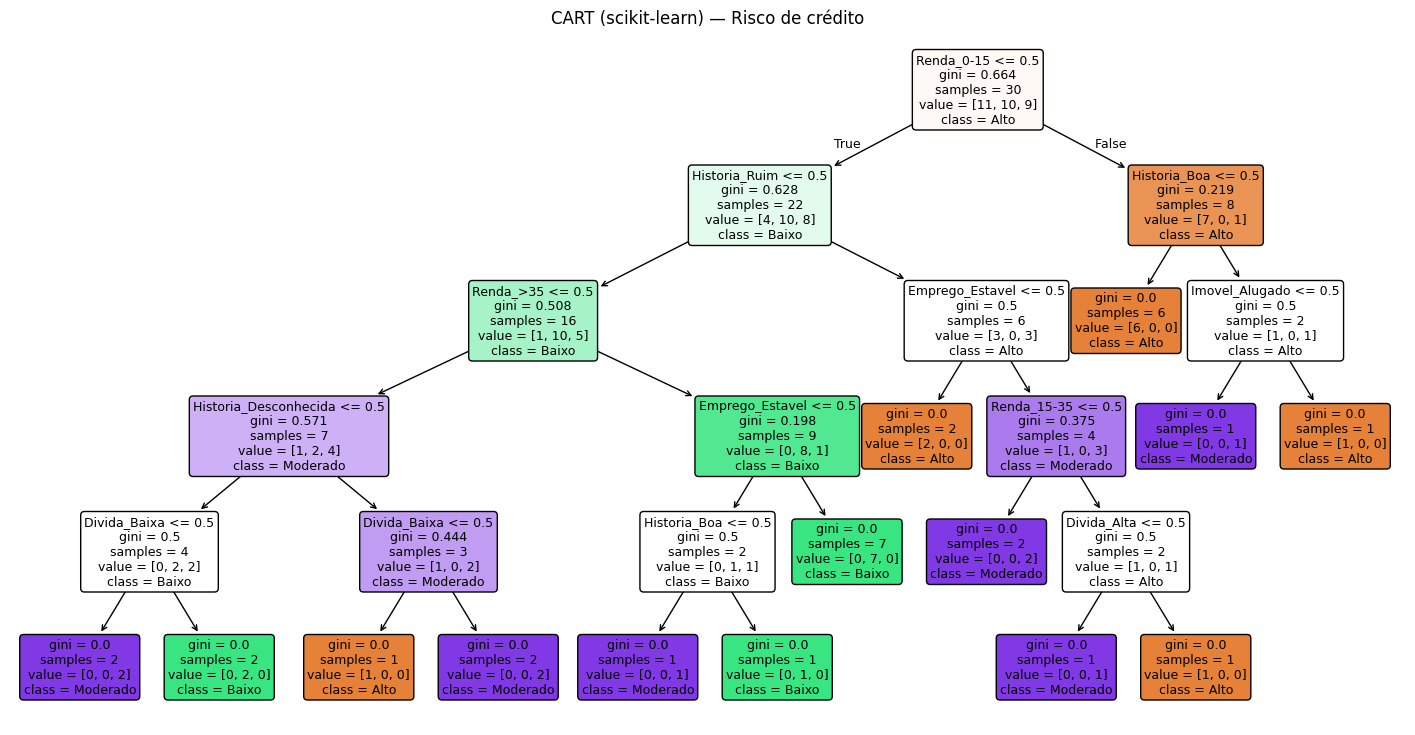

Acurácia no treino: 1.0 | folhas: 14 | profundidade: 5


In [ ]:
X = pd.get_dummies(df[atributos]).astype(int); y = df["Risco"]
cart = DecisionTreeClassifier(criterion="gini", random_state=0).fit(X, y)
plt.figure(figsize=(18, 9))
plot_tree(cart, feature_names=X.columns, class_names=cart.classes_, filled=True, rounded=True, fontsize=9)
plt.title("CART (scikit-learn) — Risco de crédito"); plt.show()
print("Acurácia no treino:", accuracy_score(y, cart.predict(X)), "| folhas:", cart.get_n_leaves(), "| profundidade:", cart.get_depth())

Extração das regras da árvore do scikit-learn. Uma pergunta como `Renda_0-15 <= 0.5` é traduzida para `Renda ≠ 0-15`.

In [ ]:
def regras_sklearn(arv, nomes, classes, X=None, y=None, dummies=True, casas=2):
    """Percorre a árvore e gera regras SE...ENTÃO já simplificadas:
    - numéricos: junta os limites do mesmo atributo (ex.: 26.9 < IMC ≤ 42.8)
    - dummies: 'Renda = 0-15' torna redundante 'Renda ≠ ...' no mesmo caminho
    Se X e y forem passados, cobertura e confiança são contadas nos exemplos reais."""
    t = arv.tree_; regras = []
    folhas = arv.apply(X) if X is not None else None
    def texto(caminho):
        if dummies:
            eq = {a: v for a, op, v in caminho if op == "="}
            out = [f"{a} = {v}" for a, v in eq.items()]
            out += [f"{a} ≠ {v}" for a, op, v in caminho if op == "≠" and a not in eq]
            return out
        lim = {}
        for a, op, v in caminho:
            lo, hi = lim.get(a, (None, None))
            lim[a] = (max(lo, v) if lo is not None else v, hi) if op == ">" else (lo, min(hi, v) if hi is not None else v)
        out = []
        for a, (lo, hi) in lim.items():
            if lo is not None and hi is not None: out.append(f"{lo:.{casas}f} < {a} ≤ {hi:.{casas}f}")
            elif lo is not None: out.append(f"{a} > {lo:.{casas}f}")
            else: out.append(f"{a} ≤ {hi:.{casas}f}")
        return out
    def rec(no, caminho):
        if t.feature[no] == _tree.TREE_UNDEFINED:
            cls = classes[int(np.argmax(t.value[no][0]))]
            if folhas is not None:
                ys = np.asarray(y)[folhas == no]; n = len(ys)
                conf = (np.array([classes[int(v)] if not isinstance(v, str) else v for v in ys]) == cls).mean()
            else:
                n = int(t.n_node_samples[no]); conf = t.value[no][0].max() / t.value[no][0].sum()
            regras.append((texto(caminho), cls, n, conf)); return
        f, lim = nomes[t.feature[no]], t.threshold[no]
        if dummies and "_" in f:
            a, val = f.split("_", 1)
            rec(t.children_left[no], caminho + [(a, "≠", val)]); rec(t.children_right[no], caminho + [(a, "=", val)])
        else:
            rec(t.children_left[no], caminho + [(f, "≤", lim)]); rec(t.children_right[no], caminho + [(f, ">", lim)])
    rec(0, []); return regras

r_cart = regras_sklearn(cart, list(X.columns), cart.classes_)
print(f"Base de regras CART/scikit-learn — {len(r_cart)} regras\n")
for i, (c, cls, n, conf) in enumerate(r_cart, 1):
    print(f"R{i:02d}: SE " + " E ".join(c) + f" ENTÃO Risco = {cls}   [{n} exemplos]")

Base de regras CART/scikit-learn — 14 regras

R01: SE Renda ≠ 0-15 E Historia ≠ Ruim E Renda ≠ >35 E Historia ≠ Desconhecida E Divida ≠ Baixa ENTÃO Risco = Moderado   [2 exemplos]
R02: SE Divida = Baixa E Renda ≠ 0-15 E Historia ≠ Ruim E Renda ≠ >35 E Historia ≠ Desconhecida ENTÃO Risco = Baixo   [2 exemplos]
R03: SE Historia = Desconhecida E Renda ≠ 0-15 E Renda ≠ >35 E Divida ≠ Baixa ENTÃO Risco = Alto   [1 exemplos]
R04: SE Historia = Desconhecida E Divida = Baixa E Renda ≠ 0-15 E Renda ≠ >35 ENTÃO Risco = Moderado   [2 exemplos]
R05: SE Renda = >35 E Historia ≠ Ruim E Emprego ≠ Estavel E Historia ≠ Boa ENTÃO Risco = Moderado   [1 exemplos]
R06: SE Renda = >35 E Historia = Boa E Emprego ≠ Estavel ENTÃO Risco = Baixo   [1 exemplos]
R07: SE Renda = >35 E Emprego = Estavel E Historia ≠ Ruim ENTÃO Risco = Baixo   [7 exemplos]
R08: SE Historia = Ruim E Renda ≠ 0-15 E Emprego ≠ Estavel ENTÃO Risco = Alto   [2 exemplos]
R09: SE Historia = Ruim E Emprego = Estavel E Renda ≠ 0-15 E Renda ≠ 1

**Resumo e verificação contra a questão 1**

In [ ]:
pd.DataFrame({
 "Algoritmo": ["ID3 (chefboost)", "C4.5 (chefboost)", "CART (chefboost, multi-vias)", "CART (scikit-learn, binário)"],
 "Critério": ["Ganho de informação", "Razão de ganho", "Gini", "Gini"],
 "Nº de regras": [len(r_id3), len(r_c45), len(r_cart_cb), len(r_cart)],
 "Máx. condições/regra": [max(len(c) for c, _ in r_id3), max(len(c) for c, _ in r_c45),
                          max(len(c) for c, _ in r_cart_cb), max(len(r[0]) for r in r_cart)],
 "Acurácia treino": ["100%"] * 4})

,Algoritmo,Critério,Nº de regras,Máx. condições/regra,Acurácia treino
0,ID3 (chefboost),Ganho de informação,15,3,100%
1,C4.5 (chefboost),Razão de ganho,14,3,100%
2,"CART (chefboost, multi-vias)",Gini,15,3,100%
3,"CART (scikit-learn, binário)",Gini,14,5,100%


In [ ]:
def conjunto(regras):
    return {(frozenset(conds), classe) for conds, classe in regras}

print("ID3 da biblioteca igual ao ID3 manual (Q1)?   ", conjunto(r_id3) == conjunto(R1_id3))
print("C4.5 da biblioteca igual ao C4.5 manual (Q1)? ", conjunto(r_c45) == conjunto(R1_c45))
print("CART do chefboost igual ao ID3 manual?         ", conjunto(r_cart_cb) == conjunto(R1_id3))
print("CART do scikit-learn acerta todos os exemplos? ", bool((cart.predict(X) == y).all()))

ID3 da biblioteca igual ao ID3 manual (Q1)?    True
C4.5 da biblioteca igual ao C4.5 manual (Q1)?  True
CART do chefboost igual ao ID3 manual?          True
CART do scikit-learn acerta todos os exemplos?  True


## Conclusão
As árvores do ID3 e do C4.5 geradas pela biblioteca ficaram idênticas às construídas manualmente na questão 1, regra por regra, o que confirma que os cálculos manuais estavam certos. O CART do chefboost, que divide em vários ramos, chegou à mesma árvore do ID3, porque nessa base o Gini e a entropia escolheram os mesmos atributos. Já o CART do scikit-learn, com perguntas binárias, ficou com 14 regras e profundidade 5, e também acerta todos os exemplos. Assim como na questão 1, o C4.5 continua sendo a base mais enxuta e legível.

---
# Questão 3

## Enunciado
Considerando uma base de dados que você vai localizar no Kaggle sobre algum domínio de aplicação específico, por exemplo em Saúde (diabetes) ou Educação (Predict students' dropout and academic success) ou Gestão de Recursos Humanos (IBM HR Analytics Employee Attrition & Performance, sobre predição de employee turnover) ou Agricultura, gere e apresente uma árvore de decisão e as regras correspondentes. Quando gerar a árvore, realize uma avaliação usando a métrica de acurácia e outras métricas: F1-Score, Precision, Recall.

Obs.: Alternativamente você poderá escolher uma outra base de dados, inclusive de outro repositório.

## Raciocínio
Foi escolhida a base **Pima Indians Diabetes Database** ([Kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)), do domínio de saúde. Ela tem 768 pacientes, 8 atributos clínicos e a classe "tem diabetes" (1) ou "não tem" (0).

O caminho foi:
1. Tratar os dados ausentes. Nessa base, um zero em glicose, pressão, pele, insulina ou IMC significa valor faltando.
2. Separar 70% para treino e 30% para teste, mantendo a proporção das classes.
3. Ajustar a árvore com validação cruzada, limitando a profundidade para evitar overfitting e para as regras ficarem legíveis.
4. Usar **pesos de classe balanceados**. Só 35% dos pacientes são diabéticos, e sem os pesos a árvore tende a dizer "não" e deixar doentes passarem.
5. Avaliar no conjunto de teste com acurácia, precision, recall e F1.

| Atributo | Significado |
|---|---|
| Gestacoes | número de gestações |
| Glicose | glicose plasmática 2h após teste oral de tolerância (mg/dL) |
| PressaoArterial | pressão diastólica (mmHg) |
| EspessuraPele | dobra cutânea do tríceps (mm) |
| Insulina | insulina sérica 2h (µU/mL) |
| IMC | índice de massa corporal |
| HistFamiliar | Diabetes Pedigree Function (histórico familiar) |
| Idade | anos |
| Diabetes | classe: 0 = não, 1 = sim |

## Resolução

**Carregamento da base**

In [ ]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
# (mesmo conteúdo do diabetes.csv do Kaggle; troque pelo caminho do arquivo baixado se preferir)
nomes = ["Gestacoes","Glicose","PressaoArterial","EspessuraPele","Insulina","IMC","HistFamiliar","Idade","Diabetes"]
dia = pd.read_csv(URL, header=None, names=nomes)
print(dia.shape); print(dia["Diabetes"].value_counts().rename({0:"Não",1:"Sim"}).to_dict())
dia.describe().round(2)

(768, 9)
{'Não': 500, 'Sim': 268}


,Gestacoes,Glicose,PressaoArterial,EspessuraPele,Insulina,IMC,HistFamiliar,Idade,Diabetes
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


**Tratamento dos ausentes e divisão treino/teste.** Os ausentes são preenchidos com a mediana do treino, para não usar informação do teste.

In [ ]:
ausentes = ["Glicose","PressaoArterial","EspessuraPele","Insulina","IMC"]
dia[ausentes] = dia[ausentes].replace(0, np.nan)
print("Valores ausentes:\n", dia.isna().sum()[ausentes].to_dict())
X = dia.drop(columns="Diabetes"); y = dia["Diabetes"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
mediana = Xtr.median(); Xtr = Xtr.fillna(mediana); Xte = Xte.fillna(mediana)
print("Treino:", Xtr.shape, "| Teste:", Xte.shape)

Valores ausentes:
 {'Glicose': 5, 'PressaoArterial': 35, 'EspessuraPele': 227, 'Insulina': 374, 'IMC': 11}
Treino: (537, 8) | Teste: (231, 8)


**Treinamento com busca de hiperparâmetros** (validação cruzada estratificada de 5 folds, otimizando o F1)

In [ ]:
grade = {"max_depth": [2,3,4,5], "min_samples_leaf": [5,10,20], "criterion": ["gini","entropy"]}
busca = GridSearchCV(DecisionTreeClassifier(random_state=42, class_weight="balanced"), grade, scoring="f1",
                     cv=StratifiedKFold(5, shuffle=True, random_state=42)).fit(Xtr, ytr)
print("Melhores hiperparâmetros:", busca.best_params_, "| F1 médio (CV):", round(busca.best_score_, 3))
arv = busca.best_estimator_

Melhores hiperparâmetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 10} | F1 médio (CV): 0.67


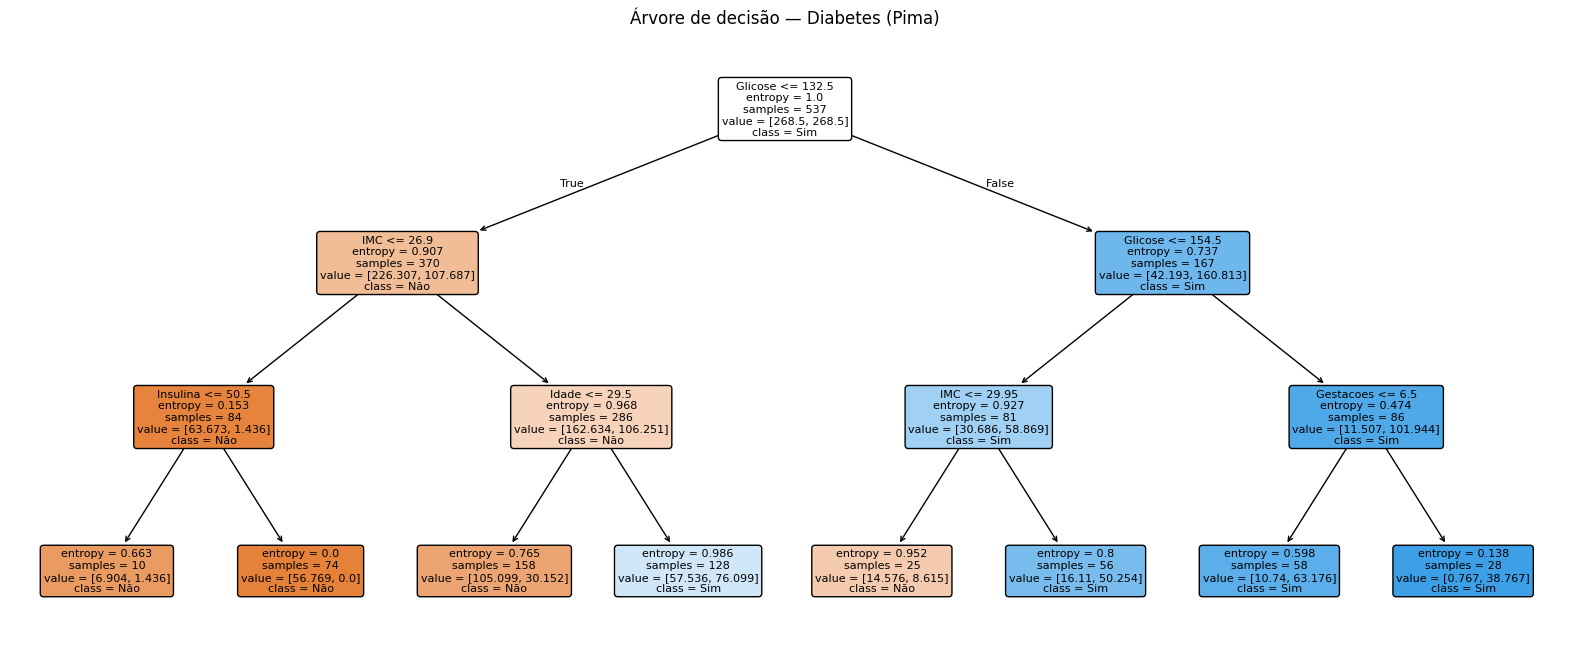

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(arv, feature_names=X.columns, class_names=["Não","Sim"], filled=True, rounded=True, fontsize=8, proportion=False)
plt.title("Árvore de decisão — Diabetes (Pima)"); plt.show()

**Avaliação no conjunto de teste**

- **Acurácia:** porcentagem de acertos no total.
- **Precision:** dos pacientes que o modelo classificou como diabéticos, quantos realmente são.
- **Recall:** dos diabéticos reais, quantos o modelo encontrou.
- **F1-Score:** média harmônica entre precision e recall.

Acurácia    0.745
Precisão    0.604
Recall      0.790
F1-Score    0.684

                precision    recall  f1-score   support

Não diabético      0.864     0.720     0.785       150
    Diabético      0.604     0.790     0.684        81

     accuracy                          0.745       231
    macro avg      0.734     0.755     0.735       231
 weighted avg      0.773     0.745     0.750       231



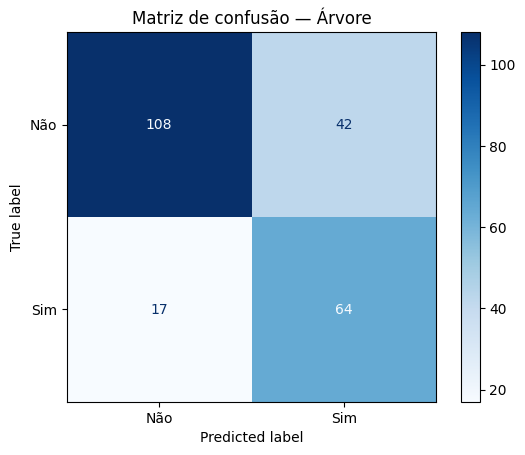

In [ ]:
def avaliar(y_true, y_pred, nome):
    return {"Modelo": nome, "Acurácia": accuracy_score(y_true, y_pred), "Precisão": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1-Score": f1_score(y_true, y_pred)}

pred = arv.predict(Xte)
res_arvore = avaliar(yte, pred, "Árvore de decisão (CART, balanceada)")
print(pd.Series(res_arvore).drop("Modelo").astype(float).round(3).to_string())
print("\n", classification_report(yte, pred, target_names=["Não diabético","Diabético"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["Não","Sim"]).plot(cmap="Blues")
plt.title("Matriz de confusão — Árvore"); plt.show()

**Regras extraídas da árvore** (cobertura = exemplos de treino que caem na regra; confiança = acerto real nesses exemplos)

In [ ]:
r_dia = regras_sklearn(arv, list(X.columns), ["Não","Sim"], X=Xtr, y=ytr, dummies=False, casas=1)
print(f"{len(r_dia)} regras\n")
for i, (c, cls, n, conf) in enumerate(r_dia, 1):
    print(f"R{i:02d}: SE " + " E ".join(c) + f" ENTÃO Diabetes = {cls}   [cobertura={n}, confiança={conf:.0%}]")

8 regras

R01: SE Glicose ≤ 132.5 E IMC ≤ 26.9 E Insulina ≤ 50.5 ENTÃO Diabetes = Não   [cobertura=10, confiança=90%]
R02: SE Glicose ≤ 132.5 E IMC ≤ 26.9 E Insulina > 50.5 ENTÃO Diabetes = Não   [cobertura=74, confiança=100%]
R03: SE Glicose ≤ 132.5 E IMC > 26.9 E Idade ≤ 29.5 ENTÃO Diabetes = Não   [cobertura=158, confiança=87%]
R04: SE Glicose ≤ 132.5 E IMC > 26.9 E Idade > 29.5 ENTÃO Diabetes = Sim   [cobertura=128, confiança=41%]
R05: SE 132.5 < Glicose ≤ 154.5 E IMC ≤ 29.9 ENTÃO Diabetes = Não   [cobertura=25, confiança=76%]
R06: SE 132.5 < Glicose ≤ 154.5 E IMC > 29.9 ENTÃO Diabetes = Sim   [cobertura=56, confiança=62%]
R07: SE Glicose > 154.5 E Gestacoes ≤ 6.5 ENTÃO Diabetes = Sim   [cobertura=58, confiança=76%]
R08: SE Glicose > 154.5 E Gestacoes > 6.5 ENTÃO Diabetes = Sim   [cobertura=28, confiança=96%]


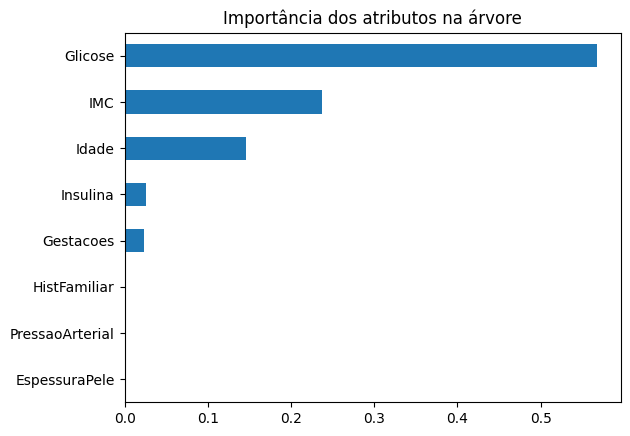

In [ ]:
imp = pd.Series(arv.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(title="Importância dos atributos na árvore"); plt.show()

## Conclusão
A árvore final tem profundidade 3 e gera 8 regras. No conjunto de teste, ela teve **acurácia de 74,5%, precision de 60,4%, recall de 79,0% e F1 de 68,4%** na classe diabético. O recall alto é o ponto mais importante: o modelo encontra cerca de 8 em cada 10 diabéticos, que é o que se espera de uma triagem em saúde. A precision mais baixa é o preço disso, já que alguns não diabéticos são encaminhados para investigação.

Nas regras, a **glicose** é o atributo decisivo. Ela aparece em todas as regras, com o primeiro corte em 132,5 mg/dL, seguida de IMC, idade e número de gestações. Com glicose acima de 154,5 e mais de 6 gestações, a confiança de diabetes chega a 96%. A regra 4 prevê "Sim" com apenas 41% de confiança no treino. Isso é efeito dos pesos balanceados: o modelo prefere marcar o caso para investigação a arriscar um falso negativo.

---
# Questão 4

## Enunciado
Na base de dados escolhida em 3), rode um algoritmo que gera regras diretamente, por exemplo o algoritmo PRISM. Apresente a base de dados com as regras geradas, também mostrando métricas de desempenho.

## Raciocínio
O PRISM gera regras sem construir árvore, por **cobertura sequencial**. Para cada classe, ele começa com uma regra vazia e vai acrescentando a condição "atributo = valor" com a maior proporção de acertos (p/t), até a regra só cobrir exemplos daquela classe. Depois guarda a regra, remove os exemplos que ela cobre e repete o processo até cobrir todos os exemplos da classe.

Como o PRISM só trabalha com atributos categóricos, os valores numéricos foram transformados em faixas com significado clínico, por exemplo IMC abaixo de 25 = Normal, de 25 a 30 = Sobrepeso e 30 ou mais = Obeso. Para classificar, as regras são aplicadas em ordem de confiança e a primeira que casar decide. As bibliotecas atuais não trazem o PRISM, então ele foi implementado.

Foram testadas duas versões: o PRISM **original**, que só aceita regras 100% corretas no treino, e uma versão com **cobertura mínima**, que só aceita condições que cubram um número mínimo de exemplos, para evitar regras específicas demais. O valor da cobertura mínima foi escolhido por validação cruzada.

## Resolução

**Base de dados discretizada** (primeiras linhas do treino)

In [ ]:
FAIXAS = {
 "Gestacoes":       ([-1, 1, 5, 99],       ["0a1", "2a5", "6+"]),
 "Glicose":         ([0, 99, 139, 999],    ["Baixa", "Normal", "Alta"]),
 "PressaoArterial": ([0, 79, 89, 999],     ["Normal", "Elevada", "Alta"]),
 "EspessuraPele":   ([0, 22, 32, 999],     ["Fina", "Media", "Grossa"]),
 "Insulina":        ([0, 99, 199, 9999],   ["Baixa", "Normal", "Alta"]),
 "IMC":             ([0, 24.99, 29.99, 999],["Normal", "Sobrepeso", "Obeso"]),
 "HistFamiliar":    ([0, 0.3, 0.6, 99],    ["Baixo", "Medio", "Alto"]),
 "Idade":           ([0, 29, 45, 999],     ["Jovem", "Adulto", "Maduro"])}
discretizar = lambda df_: pd.DataFrame({c: pd.cut(df_[c], b, labels=l).astype(str) for c, (b, l) in FAIXAS.items()}, index=df_.index)
Dtr, Dte = discretizar(Xtr), discretizar(Xte)
ytr_s = ytr.map({0: "Não", 1: "Sim"}); yte_s = yte.map({0: "Não", 1: "Sim"})
pd.concat([Dtr, ytr_s.rename("Diabetes")], axis=1).head(10)

,Gestacoes,Glicose,PressaoArterial,EspessuraPele,Insulina,IMC,HistFamiliar,Idade,Diabetes
209,6+,Alta,Elevada,Grossa,Normal,Obeso,Medio,Adulto,Sim
176,6+,Baixa,Normal,Media,Normal,Obeso,Medio,Adulto,Não
147,2a5,Normal,Normal,Grossa,Normal,Obeso,Alto,Adulto,Não
454,2a5,Normal,Normal,Media,Normal,Obeso,Medio,Jovem,Não
636,2a5,Normal,Normal,Media,Normal,Sobrepeso,Baixo,Maduro,Não
611,2a5,Alta,Normal,Fina,Normal,Obeso,Medio,Adulto,Sim
608,0a1,Alta,Elevada,Grossa,Alta,Obeso,Baixo,Jovem,Não
694,2a5,Baixa,Normal,Media,Normal,Normal,Baixo,Jovem,Não
473,6+,Normal,Alta,Media,Normal,Sobrepeso,Baixo,Maduro,Não
47,2a5,Baixa,Normal,Media,Normal,Sobrepeso,Medio,Jovem,Não


**Implementação do PRISM**

In [ ]:
def prism(D, y, cobertura_min=1, verbose=False):
    """PRISM de Cendrowska. cobertura_min=1 -> PRISM original (regras 100% puras no treino).
    cobertura_min>1 -> só aceita termos que cubram pelo menos esse nº de exemplos (reduz overfitting)."""
    regras = []
    for classe in sorted(y.unique()):
        E, Y = D.copy(), y.copy()
        while (Y == classe).any():
            cond, S, SY = {}, E, Y
            while not (SY == classe).all() and len(cond) < D.shape[1]:
                melhor = None
                for a in D.columns:
                    if a in cond: continue
                    for v in S[a].unique():
                        m = S[a] == v; t = int(m.sum()); p = int(((SY == classe) & m).sum())
                        if t < cobertura_min or p == 0: continue
                        if melhor is None or (p/t, p) > melhor[0]: melhor = ((p/t, p), a, v)
                if melhor is None: break
                (_, a, v) = melhor; cond[a] = v
                if verbose: print(f"   + {a} = {v}  (p/t = {melhor[0][1]}/{round(melhor[0][1]/melhor[0][0])})")
                m = S[a] == v; S, SY = S[m], SY[m]
            if not cond: break
            cob = np.logical_and.reduce([(E[a] == v).values for a, v in cond.items()])
            pos = (Y == classe).values & cob
            regras.append({"cond": cond, "classe": classe, "p": int(pos.sum()), "t": int(cob.sum())})
            if verbose: print(f"=> R{len(regras)}: SE {cond} ENTÃO {classe}  [{pos.sum()}/{cob.sum()}]")
            E, Y = E[~pos], Y[~pos]
    return sorted(regras, key=lambda r: (-r["p"]/r["t"], -r["p"]))   # lista de decisão por confiança

def prever_prism(regras, D, padrao):
    saida = []
    for _, ex in D.iterrows():
        saida.append(next((r["classe"] for r in regras if all(ex[a] == v for a, v in r["cond"].items())), padrao))
    return np.array(saida)

def mostrar_prism(regras, n=None):
    for i, r in enumerate(regras[:n], 1):
        print(f"R{i:03d}: SE " + " E ".join(f"{a} = {v}" for a, v in r["cond"].items())
              + f" ENTÃO Diabetes = {r['classe']}   [acertos {r['p']}/{r['t']}]")

**Processo de construção** (demonstração na base de crédito, que é pequena: cada linha `+` é uma condição adicionada e cada `=>` é uma regra concluída)

In [ ]:
_ = prism(df[atributos], df["Risco"], verbose=True)

   + Renda = 0-15  (p/t = 7/8)
   + Imovel = Alugado  (p/t = 6/6)
=> R1: SE {'Renda': '0-15', 'Imovel': 'Alugado'} ENTÃO Alto  [6/6]
   + Historia = Ruim  (p/t = 4/7)
   + Emprego = Instavel  (p/t = 3/3)
=> R2: SE {'Historia': 'Ruim', 'Emprego': 'Instavel'} ENTÃO Alto  [3/3]
   + Divida = Alta  (p/t = 2/8)
   + Emprego = Instavel  (p/t = 1/1)
=> R3: SE {'Divida': 'Alta', 'Emprego': 'Instavel'} ENTÃO Alto  [1/1]
   + Historia = Ruim  (p/t = 1/4)
   + Divida = Alta  (p/t = 1/2)
   + Renda = 15-35  (p/t = 1/1)
=> R4: SE {'Historia': 'Ruim', 'Divida': 'Alta', 'Renda': '15-35'} ENTÃO Alto  [1/1]
   + Renda = >35  (p/t = 8/12)
   + Historia = Boa  (p/t = 5/5)
=> R5: SE {'Renda': '>35', 'Historia': 'Boa'} ENTÃO Baixo  [5/5]
   + Imovel = Proprio  (p/t = 5/10)
   + Renda = >35  (p/t = 3/4)
   + Emprego = Estavel  (p/t = 3/3)
=> R6: SE {'Imovel': 'Proprio', 'Renda': '>35', 'Emprego': 'Estavel'} ENTÃO Baixo  [3/3]
   + Historia = Boa  (p/t = 2/6)
   + Divida = Baixa  (p/t = 2/3)
   + Renda = 15-

**PRISM original na base de diabetes** (primeiras 25 regras)

In [ ]:
padrao = ytr_s.mode()[0]
r_prism = prism(Dtr, ytr_s, cobertura_min=1)
pred_p = prever_prism(r_prism, Dte, padrao)
res_prism = avaliar((yte_s == "Sim").astype(int), (pred_p == "Sim").astype(int), "PRISM original")
print(f"{len(r_prism)} regras geradas. Primeiras 25 (ordenadas por confiança):\n")
mostrar_prism(r_prism, 25)

227 regras geradas. Primeiras 25 (ordenadas por confiança):

R001: SE IMC = Normal E Glicose = Baixa ENTÃO Diabetes = Não   [acertos 25/25]
R002: SE Insulina = Baixa E HistFamiliar = Baixo E PressaoArterial = Normal ENTÃO Diabetes = Não   [acertos 21/21]
R003: SE IMC = Normal E Glicose = Normal E Insulina = Normal ENTÃO Diabetes = Não   [acertos 18/18]
R004: SE IMC = Sobrepeso E Gestacoes = 0a1 E Idade = Jovem ENTÃO Diabetes = Não   [acertos 15/15]
R005: SE Glicose = Baixa E HistFamiliar = Medio E IMC = Sobrepeso ENTÃO Diabetes = Não   [acertos 13/13]
R006: SE Glicose = Baixa E HistFamiliar = Medio E Idade = Jovem E EspessuraPele = Media ENTÃO Diabetes = Não   [acertos 11/11]
R007: SE Glicose = Baixa E Idade = Jovem E EspessuraPele = Fina ENTÃO Diabetes = Não   [acertos 10/10]
R008: SE Glicose = Alta E HistFamiliar = Medio E Gestacoes = 6+ E IMC = Obeso ENTÃO Diabetes = Sim   [acertos 10/10]
R009: SE Glicose = Baixa E EspessuraPele = Grossa E Idade = Adulto ENTÃO Diabetes = Não   [acer

In [ ]:
print(pd.Series(res_prism).drop("Modelo").astype(float).round(3).to_string())
print(classification_report(yte_s, pred_p, digits=3))

Acurácia    0.701
Precisão    0.594
Recall      0.469
F1-Score    0.524
              precision    recall  f1-score   support

         Não      0.743     0.827     0.782       150
         Sim      0.594     0.469     0.524        81

    accuracy                          0.701       231
   macro avg      0.668     0.648     0.653       231
weighted avg      0.690     0.701     0.692       231



**Escolha da cobertura mínima por validação cruzada no treino**

In [ ]:
skf = StratifiedKFold(5, shuffle=True, random_state=42); cv_res = {}
for cm in [1, 5, 10, 15, 20, 30]:
    f1s = []
    for a, b in skf.split(Dtr, ytr_s):
        R = prism(Dtr.iloc[a], ytr_s.iloc[a], cm)
        pr = prever_prism(R, Dtr.iloc[b], padrao)
        f1s.append(f1_score(ytr_s.iloc[b], pr, pos_label="Sim"))
    cv_res[cm] = np.mean(f1s)
print({k: round(v, 3) for k, v in cv_res.items()})
melhor_cm = max(cv_res, key=cv_res.get); print("Cobertura mínima escolhida:", melhor_cm)

{1: np.float64(0.536), 5: np.float64(0.557), 10: np.float64(0.585), 15: np.float64(0.584), 20: np.float64(0.592), 30: np.float64(0.584)}
Cobertura mínima escolhida: 20


**Base de regras final** (PRISM com a cobertura mínima escolhida)

In [ ]:
r_prism2 = prism(Dtr, ytr_s, cobertura_min=melhor_cm)
pred_p2 = prever_prism(r_prism2, Dte, padrao)
res_prism2 = avaliar((yte_s == "Sim").astype(int), (pred_p2 == "Sim").astype(int), f"PRISM (cobertura mín. {melhor_cm})")
print(f"{len(r_prism2)} regras:\n"); mostrar_prism(r_prism2)

53 regras:

R001: SE IMC = Normal E Glicose = Baixa ENTÃO Diabetes = Não   [acertos 25/25]
R002: SE Insulina = Baixa E HistFamiliar = Baixo E PressaoArterial = Normal ENTÃO Diabetes = Não   [acertos 23/23]
R003: SE IMC = Normal E Glicose = Normal E Insulina = Normal ENTÃO Diabetes = Não   [acertos 21/21]
R004: SE Glicose = Baixa E HistFamiliar = Medio E Idade = Jovem E PressaoArterial = Normal E IMC = Obeso ENTÃO Diabetes = Não   [acertos 19/20]
R005: SE Glicose = Baixa E Idade = Jovem E PressaoArterial = Normal ENTÃO Diabetes = Não   [acertos 21/23]
R006: SE Glicose = Alta E HistFamiliar = Medio E IMC = Obeso E Insulina = Normal ENTÃO Diabetes = Sim   [acertos 21/23]
R007: SE Glicose = Baixa E HistFamiliar = Medio E PressaoArterial = Normal ENTÃO Diabetes = Não   [acertos 19/21]
R008: SE IMC = Sobrepeso E Gestacoes = 0a1 E Insulina = Normal ENTÃO Diabetes = Não   [acertos 19/21]
R009: SE Glicose = Normal E Idade = Jovem E HistFamiliar = Baixo E IMC = Obeso E Insulina = Normal ENTÃO Di

              precision    recall  f1-score   support

         Não      0.800     0.800     0.800       150
         Sim      0.630     0.630     0.630        81

    accuracy                          0.740       231
   macro avg      0.715     0.715     0.715       231
weighted avg      0.740     0.740     0.740       231



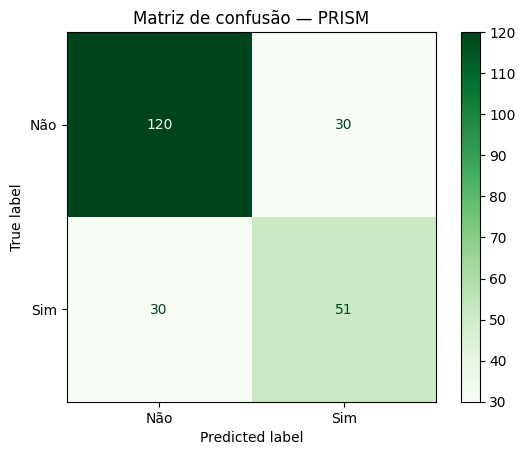

In [ ]:
print(classification_report(yte_s, pred_p2, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yte_s, pred_p2, labels=["Não","Sim"]), display_labels=["Não","Sim"]).plot(cmap="Greens")
plt.title("Matriz de confusão — PRISM"); plt.show()

**Comparação com a árvore da questão 3** (conjunto de teste)

In [ ]:
comp = pd.DataFrame([res_arvore, res_prism, res_prism2]).set_index("Modelo").round(3)
comp["Nº de regras"] = [len(r_dia), len(r_prism), len(r_prism2)]
comp

,Acurácia,Precisão,Recall,F1-Score,Nº de regras
Modelo,,,,,
"Árvore de decisão (CART, balanceada)",0.745,0.604,0.790,0.684,8
PRISM original,0.701,0.594,0.469,0.524,227
PRISM (cobertura mín. 20),0.740,0.630,0.630,0.630,53


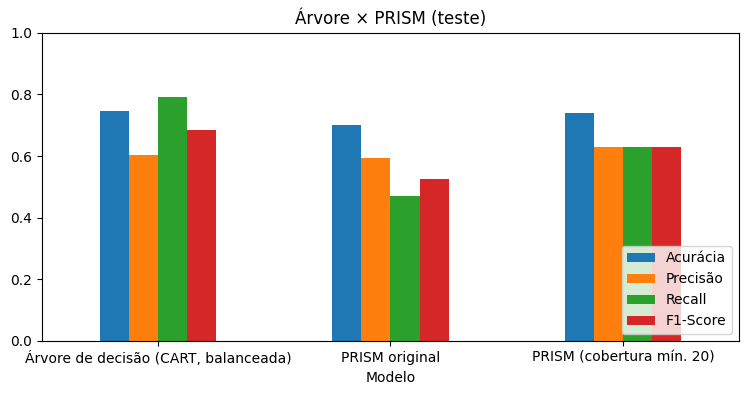

In [ ]:
comp.drop(columns="Nº de regras").plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1), title="Árvore × PRISM (teste)")
plt.legend(loc="lower right"); plt.show()

## Conclusão
O PRISM original gerou **227 regras**, muitas cobrindo um ou dois pacientes, e teve acurácia de 70,1% e F1 de 52,4% no teste. Isso mostra overfitting: ao exigir regras perfeitas no treino, ele decora casos particulares. Com a cobertura mínima de 20 exemplos, escolhida por validação cruzada, a base caiu para **53 regras** e o desempenho subiu para **acurácia de 74,0%, precision, recall e F1 de 63,0%**.

As regras confirmam o que a árvore mostrou: glicose alta, obesidade e histórico familiar levam a "Sim", enquanto glicose baixa e IMC normal levam a "Não". Mesmo assim, nesta base a árvore da questão 3 foi melhor, com F1 de 68,4% usando só 8 regras. A vantagem do PRISM é gerar regras independentes, que podem ser lidas uma a uma sem depender de um caminho de árvore.

---
# Questão 5

## Enunciado
Desenvolva uma ferramenta genérica (shell genérico) para um sistema baseado em conhecimento, contendo os módulos: base de conhecimento (regras e fatos), engenho de inferência, explicação e interface, ou seja, considerando a arquitetura conceitual de um agente baseado em conhecimento, mostrada em sala de aula. Especificamente, esta ferramenta deverá incluir os módulos: (i) um editor de base de conhecimento, (ii) um engenho de inferência com encadeamento para trás, encadeamento para frente e encadeamento misto, explicação (Por quê? Como?) e interface, desejavelmente, com diálogo em linguagem natural.

Arquitetura conceitual:

```
                  USUÁRIO
                     |
                 INTERFACE
             (diálogo / consulta)
                     |
        +------------+------------+
        |                         |
 ENGENHO DE INFERÊNCIA  <---->  EXPLICAÇÃO
  - Forward chaining            - Por quê?
  - Backward chaining           - Como?
  - Mixed chaining              - Trilha de inferência
        |
 BASE DE CONHECIMENTO
  Fatos
  Regras SE ... ENTÃO ...
        ^
        |
 EDITOR DA BASE DE CONHECIMENTO
  criar / editar / excluir regras e fatos
```

Note que a ferramenta não deve conter conhecimento específico de um domínio. Ela fornece a infraestrutura; uma aplicação concreta surge quando alguém cria uma base de conhecimento. Por exemplo, a mesma ferramenta poderia receber uma BC para diagnóstico de equipamentos, seleção de produtos, suporte técnico, classificação de animais ou recomendação de cursos.

## Raciocínio
A ideia central é separar o **conhecimento** do **raciocínio**. A classe `BaseConhecimento` só guarda variáveis, fatos e regras, e os métodos de edição formam o editor. A classe `Motor` só sabe raciocinar sobre regras genéricas do tipo SE...ENTÃO e não contém nenhuma palavra de domínio. Assim, trocar a base é suficiente para ter um sistema novo.

O motor funciona assim:
- **Encadeamento para frente (forward chaining):** parte dos fatos conhecidos e dispara toda regra cujas condições estejam satisfeitas, até não haver mais nada a disparar. Quando faltam dados, pergunta a próxima variável que aparece numa regra ainda útil.
- **Encadeamento para trás (backward chaining):** parte do objetivo, procura as regras que o concluem e tenta provar as condições delas, que viram subobjetivos. Só pergunta ao usuário o que é necessário.
- **Encadeamento misto:** primeiro para frente com os fatos que já existem, depois para trás em busca do objetivo, e de novo para frente a cada resposta.

Para a explicação, o motor guarda uma **pilha** com o objetivo e a regra em teste. O **"Por quê?"**, feito durante uma pergunta, mostra a regra em teste e, se repetido, sobe na pilha. O **"Como?"**, feito depois da conclusão, percorre de trás para frente as regras que geraram cada fato. A **trilha** registra cada passo.

A interface permite responder às perguntas pelo teclado, entende "por quê?" e "não sei", e extrai fatos de frases simples como "a renda é alta e o emprego é estável". Para as demonstrações rodarem sem digitar, há também um usuário simulado com respostas pré-definidas.



## Resolução

**Módulo 1: base de conhecimento e editor**

In [ ]:
import unicodedata, re

def norm(s):
    """minúsculas e sem acento, para comparar 'Não' com 'nao'"""
    return unicodedata.normalize("NFD", str(s)).encode("ascii", "ignore").decode().lower().strip()

def parse_cond(txt):
    m = re.match(r"^\s*(\w+)\s*(!=|≠|>=|<=|=|>|<)\s*(.+?)\s*$", txt)
    if not m: raise ValueError(f"Condição inválida: {txt!r}")
    op = "!=" if m.group(2) == "≠" else m.group(2)
    return (norm(m.group(1)), op, m.group(3).strip())

def parse_regra(texto):
    """'SE a = x E b > 3 ENTÃO c = y'  →  {'se': [(a,'=',x), (b,'>','3')], 'entao': [(c,'=',y)]}"""
    m = re.match(r"^\s*SE\s+(.+?)\s+ENT[AÃ]O\s+(.+)$", texto, re.I)
    if not m: raise ValueError("Formato: SE cond E cond ENTÃO var = valor")
    se = [parse_cond(c) for c in re.split(r"\s+E\s+", m.group(1), flags=re.I)]
    entao = [parse_cond(c) for c in re.split(r"\s+E\s+", m.group(2), flags=re.I)]
    if any(op != "=" for _, op, _ in entao): raise ValueError("A conclusão só aceita '='")
    return {"se": se, "entao": [(v, val) for v, _, val in entao]}

def texto_regra(r):
    return "SE " + " E ".join(f"{v} {op} {val}" for v, op, val in r["se"]) + \
           " ENTÃO " + " E ".join(f"{v} = {val}" for v, val in r["entao"])

class BaseConhecimento:
    """Só guarda conhecimento. Não sabe nada de inferência."""
    def __init__(self, nome, objetivo):
        self.nome, self.objetivo = nome, objetivo
        self.variaveis, self.regras, self.fatos = {}, [], {}

    # ---- editor ----
    def variavel(self, nome, pergunta=None, valores=None):
        """pergunta != None  →  o sistema pode perguntar essa variável ao usuário"""
        self.variaveis[nome] = {"pergunta": pergunta, "valores": valores or []}
    def regra(self, texto):            self.regras.append(parse_regra(texto)); return len(self.regras)
    def editar_regra(self, n, texto):  self.regras[n - 1] = parse_regra(texto)
    def excluir_regra(self, n):        del self.regras[n - 1]
    def mover_regra(self, n, nova_pos):self.regras.insert(nova_pos - 1, self.regras.pop(n - 1))
    def fato(self, var, valor):        self.fatos[var] = valor
    def excluir_fato(self, var):       self.fatos.pop(var, None)

    # ---- consultas usadas pelo motor ----
    def perguntavel(self, v):  return bool(self.variaveis.get(v, {}).get("pergunta"))
    def concluem(self, v):     return [i for i, r in enumerate(self.regras) if any(c == v for c, _ in r["entao"])]
    def listar(self):
        print(f"Base: {self.nome}   |   objetivo: {self.objetivo}")
        for i, r in enumerate(self.regras, 1): print(f"  R{i:02d}: {texto_regra(r)}")
        if self.fatos: print("  Fatos:", self.fatos)

**Módulo 2 e 3: engenho de inferência e explicação**

In [ ]:
class Motor:
    def __init__(self, bc, responder, modo="tras", estrategia="ordem", verbose=True):
        self.bc, self.responder, self.modo, self.estrategia, self.verbose = bc, responder, modo, estrategia, verbose
        self.mt = {v: {"valor": val, "origem": "fato da base"} for v, val in bc.fatos.items()}  # memória de trabalho
        self.disparadas, self.trilha, self.pilha, self.visitando = set(), [], [], set()

    def log(self, tipo, txt):
        self.trilha.append((tipo, txt))
        if self.verbose: print(f"   [{tipo:9}] {txt}")

    # ---------- avaliar uma condição: True / False / None (variável ainda desconhecida) ----------
    def avaliar(self, cond):
        v, op, val = cond
        if v not in self.mt: return None
        x = self.mt[v]["valor"]
        if x is None: return False                       # usuário respondeu "não sei"
        try: a, b = float(x), float(val)                # numérico?
        except ValueError: a, b = norm(x), norm(val)
        if op in (">", "<", ">=", "<=") and isinstance(a, str): return False
        return {"=": a == b, "!=": a != b, ">": a > b, "<": a < b, ">=": a >= b, "<=": a <= b}[op]

    def estado(self, i):  # 'verdadeira' | 'falsa' | 'aberta'
        res = [self.avaliar(c) for c in self.bc.regras[i]["se"]]
        return "falsa" if False in res else "aberta" if None in res else "verdadeira"

    def disparar(self, i):
        self.disparadas.add(i)
        for v, val in self.bc.regras[i]["entao"]:
            if v not in self.mt:
                self.mt[v] = {"valor": val, "origem": "regra", "regra": i}
                self.log("DISPARA", f"R{i+1} → {v} = {val}")
            elif norm(self.mt[v]["valor"]) != norm(val):
                self.log("CONFLITO", f"R{i+1} diria {v} = {val}, mas já vale {self.mt[v]['valor']}")

    # ---------- ENCADEAMENTO PARA FRENTE ----------
    def conjunto_conflito(self):
        return [i for i, r in enumerate(self.bc.regras) if i not in self.disparadas
                and self.estado(i) == "verdadeira" and any(v not in self.mt for v, _ in r["entao"])]

    def frente(self):
        while True:
            cc = self.conjunto_conflito()
            if not cc: return
            if self.estrategia == "especificidade": cc.sort(key=lambda i: -len(self.bc.regras[i]["se"]))
            if len(cc) > 1: self.log("AGENDA", f"conjunto de conflito {['R'+str(i+1) for i in cc]} → escolhe R{cc[0]+1}")
            self.disparar(cc[0])

    def proxima_entrada(self):
        """variável perguntável que aparece numa regra ainda útil (não disparada, não falsa, conclui algo novo)"""
        for i, r in enumerate(self.bc.regras):
            if i in self.disparadas or self.estado(i) == "falsa" or all(v in self.mt for v, _ in r["entao"]): continue
            for v, _, _ in r["se"]:
                if v not in self.mt and self.bc.perguntavel(v): return v

    # ---------- ENCADEAMENTO PARA TRÁS ----------
    def provar(self, v):
        if v in self.mt: return self.mt[v]["valor"] is not None
        if v in self.visitando: return False                     # evita ciclos
        self.visitando.add(v)
        for i in self.bc.concluem(v):
            if v in self.mt: break
            if i in self.disparadas or self.estado(i) == "falsa": continue
            self.pilha.append((v, i)); self.log("TENTA", f"objetivo {v}: R{i+1}")
            ok = self.tentar(i, v)
            self.pilha.pop()
            if ok and i not in self.disparadas: self.disparar(i)
            elif not ok and v not in self.mt: self.log("FALHA", f"R{i+1} não se aplica")
        if v not in self.mt and self.bc.perguntavel(v): self.perguntar(v)
        self.visitando.discard(v)
        return v in self.mt and self.mt[v]["valor"] is not None

    def tentar(self, i, objetivo):
        for cond in self.bc.regras[i]["se"]:
            if self.avaliar(cond) is None:
                self.provar(cond[0])                             # condição desconhecida vira subobjetivo
                if objetivo in self.mt: return False             # (misto) concluído por outro caminho
            if self.avaliar(cond) is not True: return False
        return True

    # ---------- INTERFACE: perguntar ----------
    def perguntar(self, v):
        d, nivel = self.bc.variaveis[v], 0
        while True:
            resp = self.responder(v, d["pergunta"], d["valores"])
            if self.verbose: print(f"   PERGUNTA: {d['pergunta']}   ← usuário: {resp!r}")
            r = norm(resp)
            if r.startswith("por que") or r in ("porque", "pq", "por que?"):
                print(self.por_que(nivel)); nivel += 1; continue
            if r in ("nao sei", "?", "desconhecido"): valor = None
            elif d["valores"]:
                achados = [x for x in d["valores"] if norm(x) == r or re.search(rf"\b{norm(x)}\b", r)]
                if not achados: print(f"   (não entendi; opções: {d['valores']})"); continue
                valor = max(achados, key=len)
            else:
                m = re.search(r"-?\d+(?:[.,]\d+)?", r)
                if not m: print("   (digite um número)"); continue
                valor = m.group().replace(",", ".")
            self.mt[v] = {"valor": valor, "origem": "usuário"}
            self.log("RESPOSTA", f"{v} = {valor if valor is not None else 'desconhecido'}")
            if self.modo == "misto": self.frente()
            return

    # ---------- CONSULTA ----------
    def consultar(self, objetivo=None):
        obj = objetivo or self.bc.objetivo
        print(f"Consulta '{self.bc.nome}' | modo: {self.modo} | objetivo: {obj}")
        if self.modo == "tras":
            self.provar(obj)
        elif self.modo == "frente":
            self.frente()
            while obj not in self.mt and (v := self.proxima_entrada()):
                self.perguntar(v); self.frente()
        else:  # misto
            self.frente()
            if obj not in self.mt: self.provar(obj)
            self.frente()
        f = self.mt.get(obj)
        print(f"\nCONCLUSÃO: {obj} = {f['valor']}" if f and f["valor"] is not None else f"\nNão foi possível concluir {obj}.")
        return f["valor"] if f else None

    # ---------- EXPLICAÇÃO ----------
    def por_que(self, nivel=0):
        if nivel >= len(self.pilha):
            return f"   POR QUÊ (nível {nivel+1}): porque {self.bc.objetivo} é o objetivo da consulta."
        alvo, i = self.pilha[-1 - nivel]
        r = self.bc.regras[i]
        sabe = [f"{v} {op} {val}" for v, op, val in r["se"] if self.avaliar((v, op, val)) is True]
        falta = [f"{v} {op} {val}" for v, op, val in r["se"] if self.avaliar((v, op, val)) is None]
        return (f"   POR QUÊ (nível {nivel+1}): estou tentando provar {alvo} pela R{i+1}: {texto_regra(r)}\n"
                f"      já sei: {sabe or '-'} | falta: {falta or '-'}")

    def como(self, v, ind=0, vistos=None):
        vistos = vistos if vistos is not None else set()
        pad, f = "   " * ind, self.mt.get(v)
        if not f: print(f"{pad}• {v}: ainda desconhecido"); return
        if f["origem"] != "regra" or v in vistos:
            print(f"{pad}• {v} = {f['valor']}  ({f['origem'] if v not in vistos else 'já explicado'})"); return
        vistos.add(v); r = self.bc.regras[f["regra"]]
        print(f"{pad}• {v} = {f['valor']}  ← R{f['regra']+1}: {texto_regra(r)}, porque:")
        for x in dict.fromkeys(c[0] for c in r["se"]): self.como(x, ind + 1, vistos)

    def mostrar_trilha(self):
        for k, (t, txt) in enumerate(self.trilha, 1): print(f"{k:2d}. {t:9} {txt}")

**Módulo 4: interface**

In [ ]:
def usuario_teclado(var, pergunta, valores):
    dica = f" ({'/'.join(valores)})" if valores else ""
    return input(f"{pergunta}{dica} [ou 'por quê?', 'não sei'] ")

def usuario_simulado(respostas):
    """respostas = {variavel: resposta ou [lista de respostas em sequência]}"""
    filas = {k: list(v) if isinstance(v, list) else [v] for k, v in respostas.items()}
    return lambda var, pergunta, valores: filas[var].pop(0) if filas.get(var) else "não sei"

def interpretar(bc, frase):
    """extrai fatos 'variavel = valor' de uma frase em português"""
    fatos = {}
    for trecho in map(norm, re.split(r",|;|\s+e\s+", frase)):   # divide ANTES de tirar acentos ('é' ≠ 'e')
        for v, d in sorted(bc.variaveis.items(), key=lambda x: -len(x[0])):
            if v.replace("_", " ") in trecho and d["pergunta"]:
                resto = trecho.replace(v.replace("_", " "), " ")
                if d["valores"] == ["sim", "nao"]:
                    fatos[v] = "nao" if re.search(r"\b(nao|sem|nunca)\b", trecho) else "sim"
                else:
                    ach = [x for x in d["valores"] if re.search(rf"\b{norm(x)}\b", resto)]
                    if ach: fatos[v] = ach[0]
                break
    return fatos

def conversar(bc, modo="tras"):
    """Consulta interativa de verdade: rode e responda pelo teclado."""
    motor = Motor(bc, usuario_teclado, modo=modo)
    frase = input("Diga algo que você já sabe (ou Enter para pular): ")
    for v, val in interpretar(bc, frase).items():
        motor.mt[v] = {"valor": val, "origem": "usuário"}; print(f"   anotado: {v} = {val}")
    motor.consultar()
    if norm(input("Quer saber como cheguei nisso? (s/n) ")).startswith("s"): motor.como(bc.objetivo)
    return motor

**Demonstração com a base 1: risco de crédito**

Usa as regras do C4.5 escolhidas na questão 1, mais uma camada que transforma o risco numa decisão sobre o empréstimo. Tudo isso é apenas dado carregado na base.

In [ ]:
credito = BaseConhecimento("Risco de crédito", objetivo="decisao")
credito.variavel("historia", "Como é a história de crédito?", ["boa", "ruim", "desconhecida"])
credito.variavel("divida",   "A dívida é alta ou baixa?",      ["alta", "baixa"])
credito.variavel("garantia", "Há garantia?",                   ["adequada", "nenhuma"])
credito.variavel("renda",    "Faixa de renda (baixa até $15k, media $15–35k, alta > $35k)?", ["baixa", "media", "alta"])
credito.variavel("emprego",  "O emprego é estável ou instável?", ["estavel", "instavel"])
credito.variavel("imovel",   "Imóvel próprio ou alugado?",     ["proprio", "alugado"])
credito.variavel("risco"); credito.variavel("decisao")          # não perguntáveis: só por regras
for r in """SE renda = baixa E imovel = alugado ENTÃO risco = alto
SE renda = baixa E imovel = proprio E historia = ruim ENTÃO risco = alto
SE renda = baixa E imovel = proprio E historia = boa ENTÃO risco = moderado
SE renda = baixa E imovel = proprio E historia = desconhecida ENTÃO risco = alto
SE renda = media E divida = alta E historia = boa ENTÃO risco = moderado
SE renda = media E divida = alta E historia = ruim ENTÃO risco = alto
SE renda = media E divida = alta E historia = desconhecida ENTÃO risco = alto
SE renda = media E divida = baixa E historia = boa ENTÃO risco = baixo
SE renda = media E divida = baixa E historia = desconhecida ENTÃO risco = moderado
SE renda = media E divida = baixa E historia = ruim ENTÃO risco = moderado
SE renda = alta E historia = boa ENTÃO risco = baixo
SE renda = alta E historia = desconhecida E emprego = estavel ENTÃO risco = baixo
SE renda = alta E historia = desconhecida E emprego = instavel ENTÃO risco = moderado
SE renda = alta E historia = ruim E emprego = estavel ENTÃO risco = moderado
SE renda = alta E historia = ruim E emprego = instavel ENTÃO risco = alto
SE risco = baixo ENTÃO decisao = aprovar
SE risco = moderado E garantia = adequada ENTÃO decisao = aprovar
SE risco = moderado E garantia = nenhuma ENTÃO decisao = exigir_garantia
SE risco = alto ENTÃO decisao = negar""".split("\n"):
    credito.regra(r)
credito.listar()

Base: Risco de crédito   |   objetivo: decisao
  R01: SE renda = baixa E imovel = alugado ENTÃO risco = alto
  R02: SE renda = baixa E imovel = proprio E historia = ruim ENTÃO risco = alto
  R03: SE renda = baixa E imovel = proprio E historia = boa ENTÃO risco = moderado
  R04: SE renda = baixa E imovel = proprio E historia = desconhecida ENTÃO risco = alto
  R05: SE renda = media E divida = alta E historia = boa ENTÃO risco = moderado
  R06: SE renda = media E divida = alta E historia = ruim ENTÃO risco = alto
  R07: SE renda = media E divida = alta E historia = desconhecida ENTÃO risco = alto
  R08: SE renda = media E divida = baixa E historia = boa ENTÃO risco = baixo
  R09: SE renda = media E divida = baixa E historia = desconhecida ENTÃO risco = moderado
  R10: SE renda = media E divida = baixa E historia = ruim ENTÃO risco = moderado
  R11: SE renda = alta E historia = boa ENTÃO risco = baixo
  R12: SE renda = alta E historia = desconhecida E emprego = estavel ENTÃO risco = baixo

**Encadeamento para trás com "Por quê?" e "Como?".** O usuário simulado pergunta "por quê?" duas vezes antes de responder a história de crédito.

In [ ]:
m1 = Motor(credito, usuario_simulado({"renda": "alta", "historia": ["por quê?", "por quê?", "boa"]}), modo="tras")
m1.consultar()

Consulta 'Risco de crédito' | modo: tras | objetivo: decisao
   [TENTA    ] objetivo decisao: R16
   [TENTA    ] objetivo risco: R1
   PERGUNTA: Faixa de renda (baixa até $15k, media $15–35k, alta > $35k)?   ← usuário: 'alta'
   [RESPOSTA ] renda = alta
   [FALHA    ] R1 não se aplica
   [TENTA    ] objetivo risco: R11
   PERGUNTA: Como é a história de crédito?   ← usuário: 'por quê?'
   POR QUÊ (nível 1): estou tentando provar risco pela R11: SE renda = alta E historia = boa ENTÃO risco = baixo
      já sei: ['renda = alta'] | falta: ['historia = boa']
   PERGUNTA: Como é a história de crédito?   ← usuário: 'por quê?'
   POR QUÊ (nível 2): estou tentando provar decisao pela R16: SE risco = baixo ENTÃO decisao = aprovar
      já sei: - | falta: ['risco = baixo']
   PERGUNTA: Como é a história de crédito?   ← usuário: 'boa'
   [RESPOSTA ] historia = boa
   [DISPARA  ] R11 → risco = baixo
   [DISPARA  ] R16 → decisao = aprovar

CONCLUSÃO: decisao = aprovar


'aprovar'

In [ ]:
print("COMO?"); m1.como("decisao")

COMO?
• decisao = aprovar  ← R16: SE risco = baixo ENTÃO decisao = aprovar, porque:
   • risco = baixo  ← R11: SE renda = alta E historia = boa ENTÃO risco = baixo, porque:
      • renda = alta  (usuário)
      • historia = boa  (usuário)


**Encadeamento para frente**

In [ ]:
m2 = Motor(credito, usuario_simulado({"renda": "media", "divida": "baixa", "historia": "ruim", "garantia": "nenhuma"}), modo="frente")
m2.consultar()

Consulta 'Risco de crédito' | modo: frente | objetivo: decisao
   PERGUNTA: Faixa de renda (baixa até $15k, media $15–35k, alta > $35k)?   ← usuário: 'media'
   [RESPOSTA ] renda = media
   PERGUNTA: A dívida é alta ou baixa?   ← usuário: 'baixa'
   [RESPOSTA ] divida = baixa
   PERGUNTA: Como é a história de crédito?   ← usuário: 'ruim'
   [RESPOSTA ] historia = ruim
   [DISPARA  ] R10 → risco = moderado
   PERGUNTA: Há garantia?   ← usuário: 'nenhuma'
   [RESPOSTA ] garantia = nenhuma
   [DISPARA  ] R18 → decisao = exigir_garantia

CONCLUSÃO: decisao = exigir_garantia


'exigir_garantia'

**Encadeamento misto com fatos ditos em linguagem natural**

In [ ]:
frase = "o cliente tem renda alta, emprego estavel e a historia é desconhecida"
fatos = interpretar(credito, frase); print("Fatos extraídos:", fatos)
m3 = Motor(credito, usuario_simulado({"garantia": "nenhuma"}), modo="misto")
m3.mt.update({v: {"valor": x, "origem": "usuário"} for v, x in fatos.items()})
m3.consultar()

Fatos extraídos: {'renda': 'alta', 'emprego': 'estavel', 'historia': 'desconhecida'}
Consulta 'Risco de crédito' | modo: misto | objetivo: decisao
   [DISPARA  ] R12 → risco = baixo
   [DISPARA  ] R16 → decisao = aprovar

CONCLUSÃO: decisao = aprovar


'aprovar'

**Demonstração com a base 2: classificação de animais**, com três níveis de encadeamento (classe, tipo e animal)

In [ ]:
animais = BaseConhecimento("Animais", objetivo="animal")
for v, p in [("tem_pelo","Tem pelo?"),("da_leite","Dá leite?"),("tem_penas","Tem penas?"),("voa","Voa?"),
             ("poe_ovos","Põe ovos?"),("come_carne","Come carne?"),("tem_cascos","Tem cascos?"),("rumina","Rumina?"),
             ("cor_parda","Cor parda?"),("manchas_escuras","Manchas escuras?"),("listras_pretas","Listras pretas?"),
             ("pescoco_longo","Pescoço longo?"),("pernas_longas","Pernas longas?"),("nada","Nada?"),("voa_bem","Voa muito bem?")]:
    animais.variavel(v, p, ["sim", "nao"])
for v in ("classe", "tipo", "animal"): animais.variavel(v)
for r in """SE tem_pelo = sim ENTÃO classe = mamifero
SE da_leite = sim ENTÃO classe = mamifero
SE tem_penas = sim ENTÃO classe = ave
SE voa = sim E poe_ovos = sim ENTÃO classe = ave
SE classe = mamifero E come_carne = sim ENTÃO tipo = carnivoro
SE classe = mamifero E tem_cascos = sim ENTÃO tipo = ungulado
SE classe = mamifero E rumina = sim ENTÃO tipo = ungulado
SE tipo = carnivoro E cor_parda = sim E manchas_escuras = sim ENTÃO animal = guepardo
SE tipo = carnivoro E cor_parda = sim E listras_pretas = sim ENTÃO animal = tigre
SE tipo = ungulado E pescoco_longo = sim E pernas_longas = sim E manchas_escuras = sim ENTÃO animal = girafa
SE tipo = ungulado E listras_pretas = sim ENTÃO animal = zebra
SE classe = ave E voa = nao E pescoco_longo = sim E pernas_longas = sim ENTÃO animal = avestruz
SE classe = ave E voa = nao E nada = sim ENTÃO animal = pinguim
SE classe = ave E voa_bem = sim ENTÃO animal = albatroz""".split("\n"):
    animais.regra(r)

zebra = {"tem_pelo": "sim", "come_carne": "não", "tem_cascos": "sim", "pescoco_longo": "não", "listras_pretas": "sim"}
m4 = Motor(animais, usuario_simulado(zebra), modo="tras"); m4.consultar(); print(); m4.como("animal")

Consulta 'Animais' | modo: tras | objetivo: animal
   [TENTA    ] objetivo animal: R8
   [TENTA    ] objetivo tipo: R5
   [TENTA    ] objetivo classe: R1
   PERGUNTA: Tem pelo?   ← usuário: 'sim'
   [RESPOSTA ] tem_pelo = sim
   [DISPARA  ] R1 → classe = mamifero
   PERGUNTA: Come carne?   ← usuário: 'não'
   [RESPOSTA ] come_carne = nao
   [FALHA    ] R5 não se aplica
   [TENTA    ] objetivo tipo: R6
   PERGUNTA: Tem cascos?   ← usuário: 'sim'
   [RESPOSTA ] tem_cascos = sim
   [DISPARA  ] R6 → tipo = ungulado
   [FALHA    ] R8 não se aplica
   [TENTA    ] objetivo animal: R10
   PERGUNTA: Pescoço longo?   ← usuário: 'não'
   [RESPOSTA ] pescoco_longo = nao
   [FALHA    ] R10 não se aplica
   [TENTA    ] objetivo animal: R11
   PERGUNTA: Listras pretas?   ← usuário: 'sim'
   [RESPOSTA ] listras_pretas = sim
   [DISPARA  ] R11 → animal = zebra

CONCLUSÃO: animal = zebra

• animal = zebra  ← R11: SE tipo = ungulado E listras_pretas = sim ENTÃO animal = zebra, porque:
   • tipo = ungulad

**Demonstração com a base 3: suporte técnico**, com uma condição numérica (temperatura) e encadeamento misto

In [ ]:
suporte = BaseConhecimento("Suporte técnico", objetivo="solucao")
suporte.variavel("liga", "O PC liga?", ["sim", "nao"]); suporte.variavel("imagem", "Aparece imagem?", ["sim", "nao"])
suporte.variavel("desliga_sozinho", "Desliga sozinho?", ["sim", "nao"])
suporte.variavel("temperatura_cpu", "Temperatura da CPU (°C)?")          # sem lista de valores → numérica
suporte.variavel("ventoinha_gira", "A ventoinha gira?", ["sim", "nao"])
suporte.variavel("problema"); suporte.variavel("solucao")
for r in ["SE liga = sim E imagem = sim E desliga_sozinho = sim E temperatura_cpu > 85 ENTÃO problema = superaquecimento",
          "SE liga = sim E imagem = sim E desliga_sozinho = sim E temperatura_cpu <= 85 ENTÃO problema = fonte_instavel",
          "SE problema = superaquecimento E ventoinha_gira = nao ENTÃO solucao = trocar_ventoinha",
          "SE problema = superaquecimento E ventoinha_gira = sim ENTÃO solucao = trocar_pasta_termica",
          "SE problema = fonte_instavel ENTÃO solucao = testar_fonte"]:
    suporte.regra(r)
m5 = Motor(suporte, usuario_simulado({"liga": "sim", "imagem": "sim", "desliga_sozinho": "sim",
                                       "temperatura_cpu": "92 graus", "ventoinha_gira": "não"}), modo="misto")
m5.consultar(); print("\nTRILHA COMPLETA:"); m5.mostrar_trilha()

Consulta 'Suporte técnico' | modo: misto | objetivo: solucao
   [TENTA    ] objetivo solucao: R3
   [TENTA    ] objetivo problema: R1
   PERGUNTA: O PC liga?   ← usuário: 'sim'
   [RESPOSTA ] liga = sim
   PERGUNTA: Aparece imagem?   ← usuário: 'sim'
   [RESPOSTA ] imagem = sim
   PERGUNTA: Desliga sozinho?   ← usuário: 'sim'
   [RESPOSTA ] desliga_sozinho = sim
   PERGUNTA: Temperatura da CPU (°C)?   ← usuário: '92 graus'
   [RESPOSTA ] temperatura_cpu = 92
   [DISPARA  ] R1 → problema = superaquecimento
   PERGUNTA: A ventoinha gira?   ← usuário: 'não'
   [RESPOSTA ] ventoinha_gira = nao
   [DISPARA  ] R3 → solucao = trocar_ventoinha

CONCLUSÃO: solucao = trocar_ventoinha

TRILHA COMPLETA:
 1. TENTA     objetivo solucao: R3
 2. TENTA     objetivo problema: R1
 3. RESPOSTA  liga = sim
 4. RESPOSTA  imagem = sim
 5. RESPOSTA  desliga_sozinho = sim
 6. RESPOSTA  temperatura_cpu = 92
 7. DISPARA   R1 → problema = superaquecimento
 8. RESPOSTA  ventoinha_gira = nao
 9. DISPARA   R3 → solu

**Editor em ação:** incluir, editar, reordenar e excluir regras e fatos, e consultar de novo

In [ ]:
suporte.regra("SE liga = nao ENTÃO problema = energia")
suporte.regra("SE problema = energia ENTÃO solucao = verificar_tomada")
suporte.editar_regra(6, "SE liga = nao E imagem = nao ENTÃO problema = energia")
suporte.mover_regra(6, 1)
suporte.fato("liga", "nao")
suporte.listar()
print()
Motor(suporte, usuario_simulado({"imagem": "não"}), modo="tras").consultar()
suporte.excluir_fato("liga")

Base: Suporte técnico   |   objetivo: solucao
  R01: SE liga = nao E imagem = nao ENTÃO problema = energia
  R02: SE liga = sim E imagem = sim E desliga_sozinho = sim E temperatura_cpu > 85 ENTÃO problema = superaquecimento
  R03: SE liga = sim E imagem = sim E desliga_sozinho = sim E temperatura_cpu <= 85 ENTÃO problema = fonte_instavel
  R04: SE problema = superaquecimento E ventoinha_gira = nao ENTÃO solucao = trocar_ventoinha
  R05: SE problema = superaquecimento E ventoinha_gira = sim ENTÃO solucao = trocar_pasta_termica
  R06: SE problema = fonte_instavel ENTÃO solucao = testar_fonte
  R07: SE problema = energia ENTÃO solucao = verificar_tomada
  Fatos: {'liga': 'nao'}

Consulta 'Suporte técnico' | modo: tras | objetivo: solucao
   [TENTA    ] objetivo solucao: R4
   [TENTA    ] objetivo problema: R1
   PERGUNTA: Aparece imagem?   ← usuário: 'não'
   [RESPOSTA ] imagem = nao
   [DISPARA  ] R1 → problema = energia
   [FALHA    ] R4 não se aplica
   [TENTA    ] objetivo solucao: R7

**Consulta interativa.** Retire o `#` de uma das linhas abaixo e execute para conversar com o sistema pelo teclado.

In [ ]:
# conversar(credito, modo="tras")
# conversar(animais, modo="tras")

## Conclusão
A ferramenta atende a todos os módulos pedidos: base de conhecimento com fatos e regras, editor (incluir, editar, reordenar e excluir), engenho de inferência com encadeamento para frente, para trás e misto, explicação com "Por quê?", "Como?" e trilha, e uma interface que aceita respostas e frases simples em português.

As demonstrações mostram as diferenças entre os modos. No encadeamento para trás, com renda alta, o sistema descartou as dez regras de renda baixa e média sem perguntar nada sobre elas e precisou de só duas perguntas para chegar a "aprovar". No modo para frente, ele perguntou os dados na ordem das regras e nunca pediu emprego nem imóvel, porque as regras que os usavam já tinham sido descartadas. No modo misto, uma frase com os fatos já bastou para concluir sem nenhuma pergunta.

O mais importante é que a mesma classe `Motor` resolveu três problemas diferentes (crédito, animais e suporte técnico) sem nenhuma alteração no código, só trocando a base de conhecimento. Isso comprova que a ferramenta é genérica, como pede o enunciado.